**Anuska Nath**

**IT-UG-4**

**Assignment - 2**

**Step 1: Install and import libraries**

In [ ]:
!pip install -q ucimlrepo

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    roc_auc_score
)

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

RANDOM_STATE = 42

**Step 2: Load the Wine dataset**

In [ ]:
from ucimlrepo import fetch_ucirepo

# Fetch Wine dataset
wine = fetch_ucirepo(id=109)

X_wine = wine.data.features
y_wine = wine.data.targets

print("Wine Dataset")
print("Shape of X:", X_wine.shape)
print("Shape of y:", y_wine.shape)

print("\nFirst 5 rows:")
display(X_wine.head())

print("\nTarget distribution:")
print(y_wine.value_counts())

Wine Dataset
Shape of X: (178, 13)
Shape of y: (178, 1)

First 5 rows:


,Alcohol,Malicacid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,0D280_0D315_of_diluted_wines,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735



Target distribution:
class
2        71
1        59
3        48
Name: count, dtype: int64


**Step 3 : Convert Wine target to 1D**

In [ ]:
y_wine = y_wine.iloc[:, 0]

print(y_wine.head())
print("\nClasses:", np.unique(y_wine))

0    1
1    1
2    1
3    1
4    1
Name: class, dtype: int64

Classes: [1 2 3]


**Step 4: Load the Handwritten Digit Dataset**

In [ ]:
from sklearn.datasets import fetch_openml

digits = fetch_openml(
    name="optdigits",
    version=1,
    as_frame=False,
    parser="auto"
)

X_digits = digits.data
y_digits = digits.target.astype(int)

print("Handwritten Digit Dataset")
print("Shape of X:", X_digits.shape)
print("Shape of y:", y_digits.shape)

print("\nClasses:")
print(np.unique(y_digits))

Handwritten Digit Dataset
Shape of X: (5620, 64)
Shape of y: (5620,)

Classes:
[0 1 2 3 4 5 6 7 8 9]


**Step 5: Display handwritten digits**

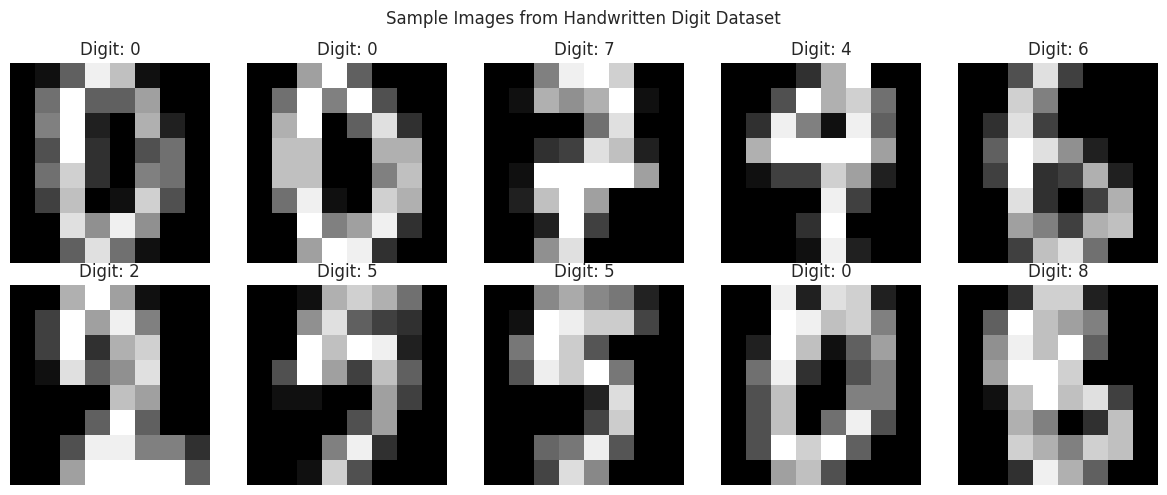

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_digits[i].reshape(8, 8), cmap="gray")
    ax.set_title(f"Digit: {y_digits[i]}")
    ax.axis("off")

plt.suptitle("Sample Images from Handwritten Digit Dataset")
plt.tight_layout()
plt.show()

**Step 6: Dataset information**

In [ ]:
print("========== WINE DATASET ==========")
print("Samples:", X_wine.shape[0])
print("Features:", X_wine.shape[1])
print("Classes:", len(np.unique(y_wine)))

print("\n========== DIGIT DATASET ==========")
print("Samples:", X_digits.shape[0])
print("Features:", X_digits.shape[1])
print("Classes:", len(np.unique(y_digits)))

========== WINE DATASET ==========
Samples: 178
Features: 13
Classes: 3

========== DIGIT DATASET ==========
Samples: 5620
Features: 64
Classes: 10


**Step 7: Create common evaluation function**

In [ ]:
def evaluate_model(model, X_train, X_test, y_train, y_test):

    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    cm = confusion_matrix(y_test, y_pred)

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Confusion Matrix": cm,
        "Model": model
    }

**Step 8: Function for confusion matrix heatmap**

In [ ]:
def plot_confusion_matrix(cm, class_names, title):

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title(title)
    plt.tight_layout()
    plt.show()

**Step 9: Function for train/test split**

In [ ]:
splits = {
    "50:50": 0.50,
    "60:40": 0.40,
    "70:30": 0.30,
    "80:20": 0.20
}

**Step 10: Standardization**

In [ ]:
def make_scaled_model(model):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", model)
    ])

**Step 11: SVM models**

In [ ]:
svm_models = {
    "SVM Linear": SVC(
        kernel="linear",
        probability=True,
        random_state=RANDOM_STATE
    ),

    "SVM Polynomial": SVC(
        kernel="poly",
        degree=3,
        probability=True,
        random_state=RANDOM_STATE
    ),

    "SVM Gaussian": SVC(
        kernel="rbf",
        probability=True,
        random_state=RANDOM_STATE
    ),

    "SVM Sigmoid": SVC(
        kernel="sigmoid",
        probability=True,
        random_state=RANDOM_STATE
    )
}

**Step 12: Run SVM on Wine for all four splits**

In [ ]:
wine_svm_results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X_wine,
        y_wine,
        test_size=test_size,
        stratify=y_wine,
        random_state=RANDOM_STATE
    )

    for model_name, svm in svm_models.items():

        model = make_scaled_model(svm)

        result = evaluate_model(
            model,
            X_train,
            X_test,
            y_train,
            y_test
        )

        wine_svm_results.append({
            "Dataset": "Wine",
            "Split": split_name,
            "Classifier": model_name,
            "Accuracy": result["Accuracy"],
            "Precision": result["Precision"],
            "Recall": result["Recall"],
            "F1 Score": result["F1 Score"],
            "Confusion Matrix": result["Confusion Matrix"],
            "Model": result["Model"]
        })

wine_svm_df = pd.DataFrame(wine_svm_results)

wine_svm_df[
    ["Dataset", "Split", "Classifier",
     "Accuracy", "Precision", "Recall", "F1 Score"]
]

,Dataset,Split,Classifier,Accuracy,Precision,Recall,F1 Score
0,Wine,50:50,SVM Linear,0.955056,0.955780,0.955056,0.954758
1,Wine,50:50,SVM Polynomial,0.853933,0.866553,0.853933,0.853971
2,Wine,50:50,SVM Gaussian,0.977528,0.977528,0.977528,0.977528
3,Wine,50:50,SVM Sigmoid,0.955056,0.956968,0.955056,0.955294
4,Wine,60:40,SVM Linear,0.958333,0.959974,0.958333,0.958336
5,Wine,60:40,SVM Polynomial,0.888889,0.902778,0.888889,0.889538
6,Wine,60:40,SVM Gaussian,0.986111,0.986574,0.986111,0.986041
7,Wine,60:40,SVM Sigmoid,1.000000,1.000000,1.000000,1.000000
8,Wine,70:30,SVM Linear,0.962963,0.963938,0.962963,0.962894
9,Wine,70:30,SVM Polynomial,0.907407,0.925214,0.907407,0.908485


**Step 13: SVM on handwritten digits**

In [ ]:
digits_svm_results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X_digits,
        y_digits,
        test_size=test_size,
        stratify=y_digits,
        random_state=RANDOM_STATE
    )

    for model_name, svm in svm_models.items():

        model = make_scaled_model(svm)

        result = evaluate_model(
            model,
            X_train,
            X_test,
            y_train,
            y_test
        )

        digits_svm_results.append({
            "Dataset": "Digits",
            "Split": split_name,
            "Classifier": model_name,
            "Accuracy": result["Accuracy"],
            "Precision": result["Precision"],
            "Recall": result["Recall"],
            "F1 Score": result["F1 Score"],
            "Confusion Matrix": result["Confusion Matrix"],
            "Model": result["Model"]
        })

digits_svm_df = pd.DataFrame(digits_svm_results)

digits_svm_df[
    ["Dataset", "Split", "Classifier",
     "Accuracy", "Precision", "Recall", "F1 Score"]
]

,Dataset,Split,Classifier,Accuracy,Precision,Recall,F1 Score
0,Digits,50:50,SVM Linear,0.973665,0.973832,0.973665,0.973687
1,Digits,50:50,SVM Polynomial,0.974377,0.976763,0.974377,0.974915
2,Digits,50:50,SVM Gaussian,0.981495,0.981805,0.981495,0.981535
3,Digits,50:50,SVM Sigmoid,0.943060,0.944040,0.943060,0.943263
4,Digits,60:40,SVM Linear,0.974644,0.974765,0.974644,0.974638
5,Digits,60:40,SVM Polynomial,0.977758,0.979585,0.977758,0.978163
6,Digits,60:40,SVM Gaussian,0.985320,0.985475,0.985320,0.985335
7,Digits,60:40,SVM Sigmoid,0.945730,0.946305,0.945730,0.945877
8,Digits,70:30,SVM Linear,0.978648,0.978933,0.978648,0.978676
9,Digits,70:30,SVM Polynomial,0.976868,0.979458,0.976868,0.977428


**Step 14: Generate SVM confusion matrices**

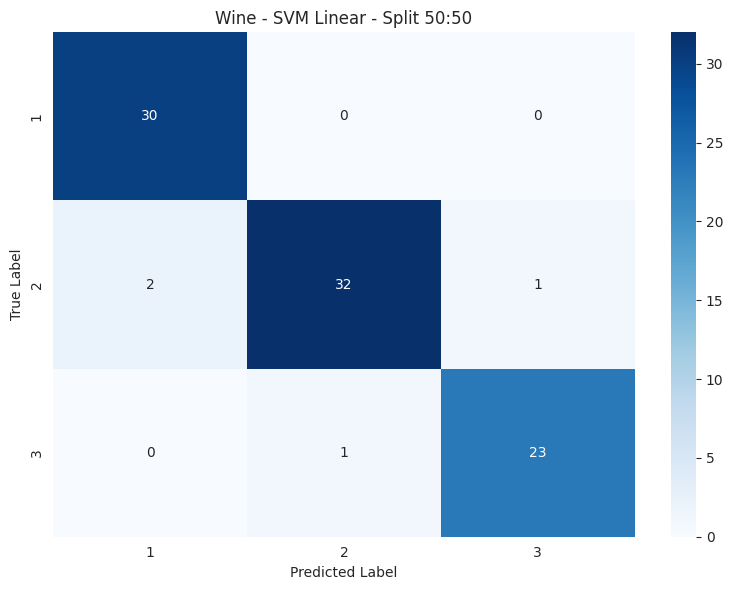

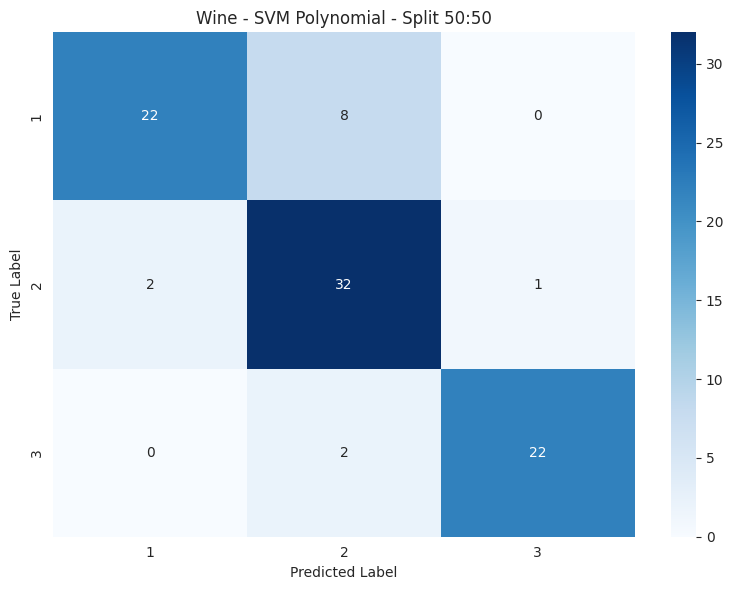

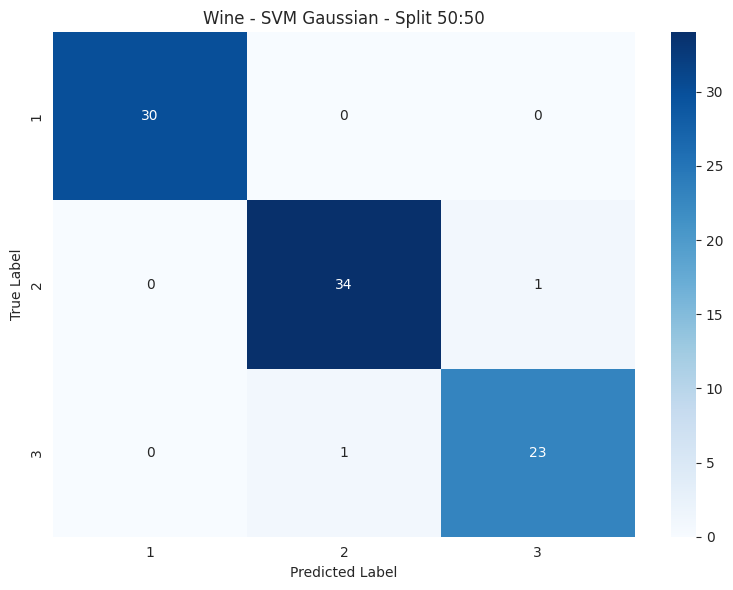

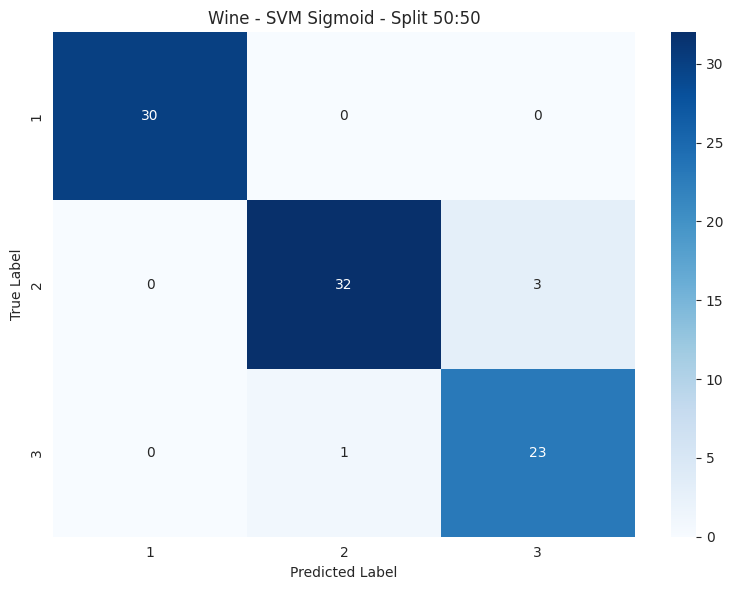

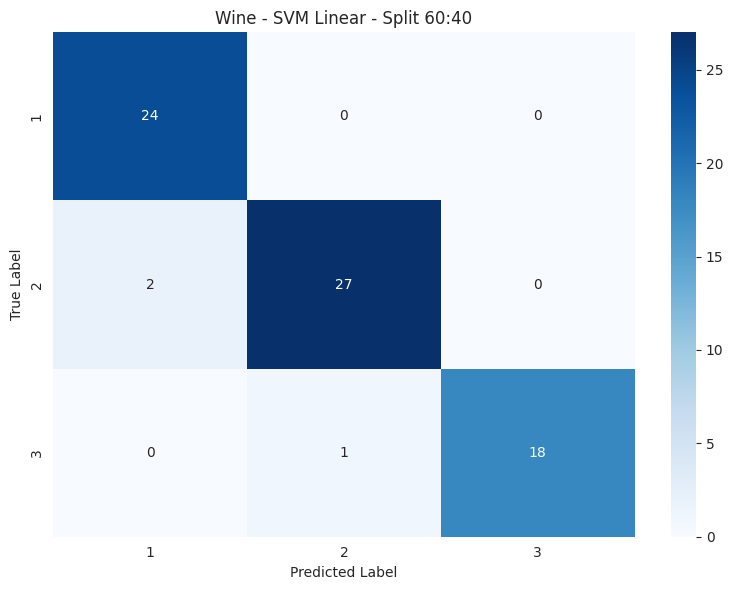

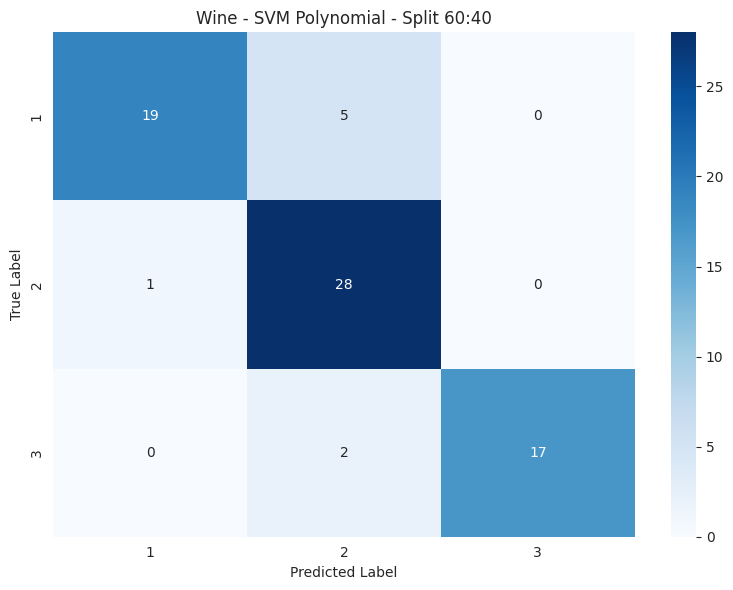

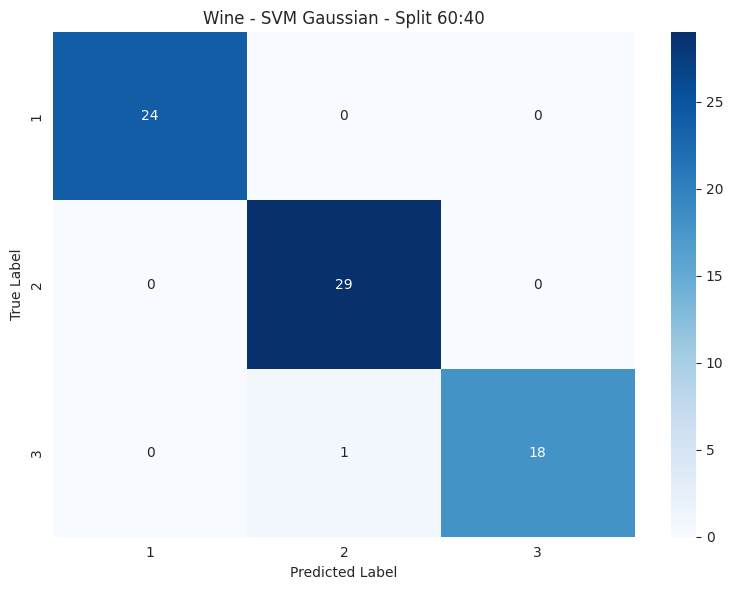

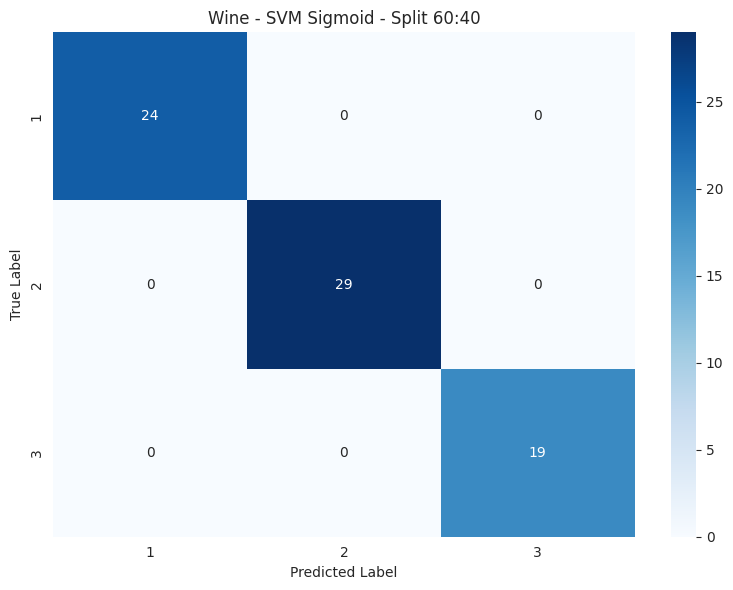

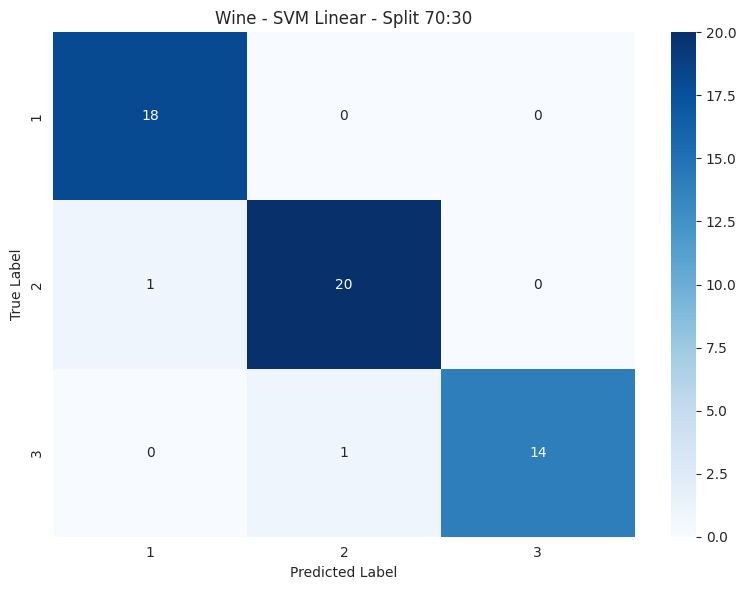

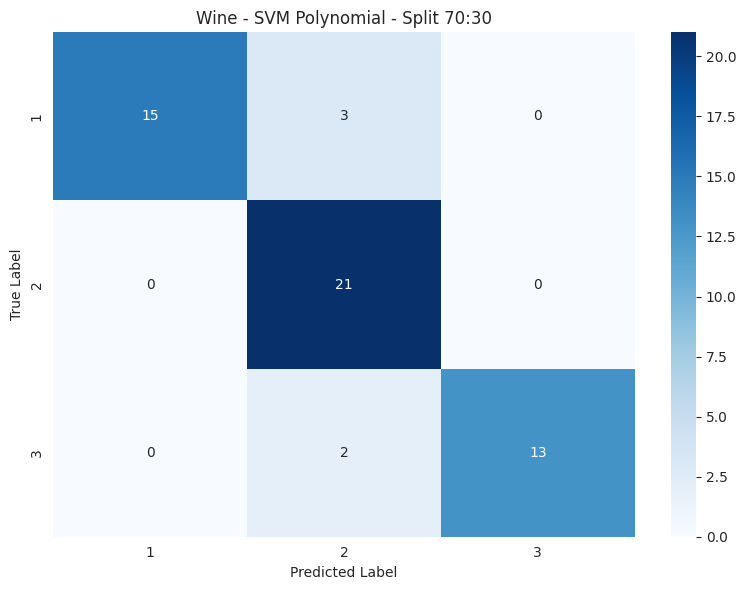

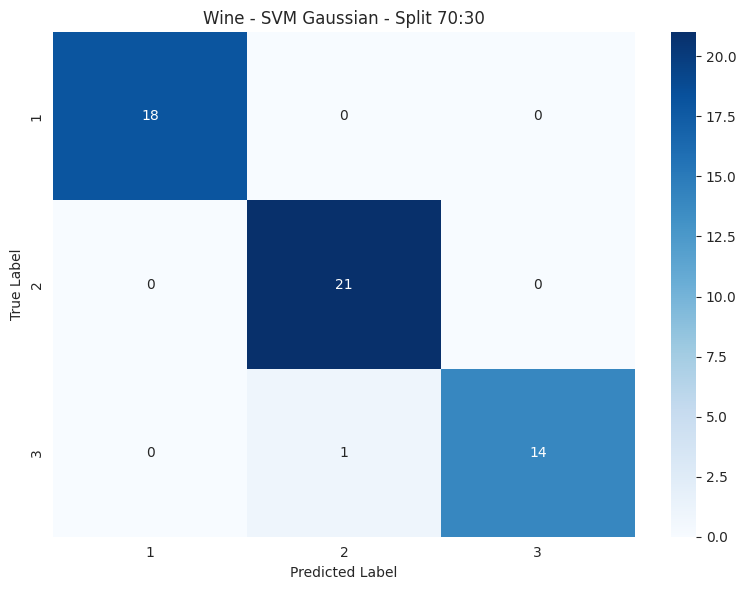

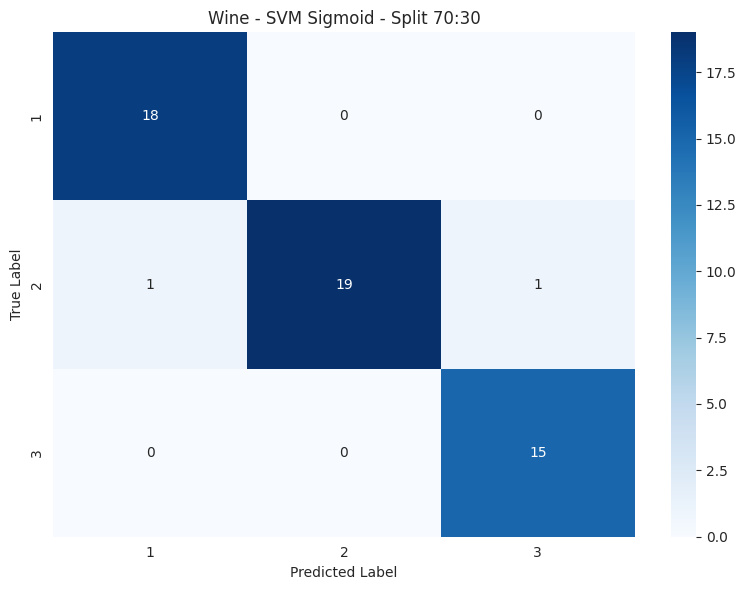

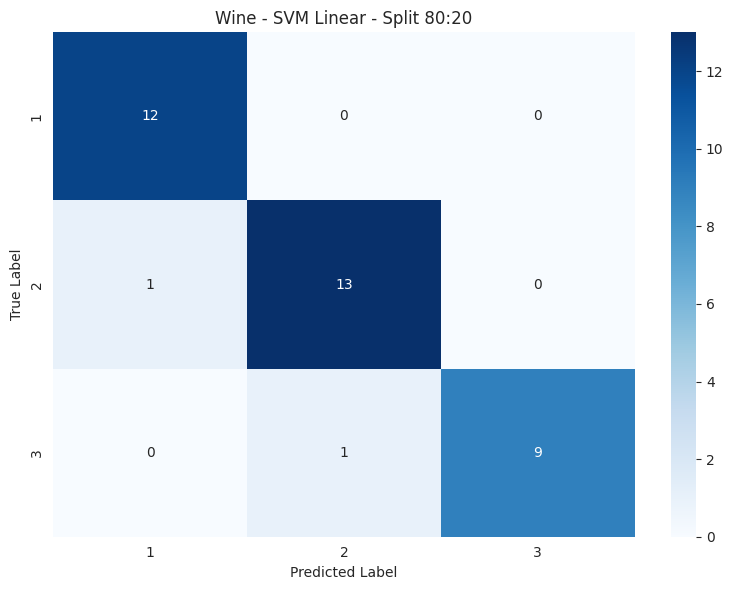

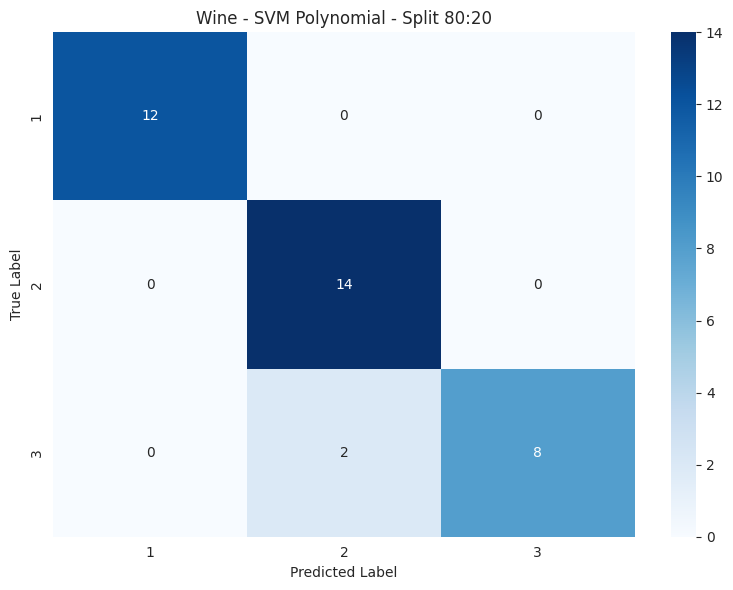

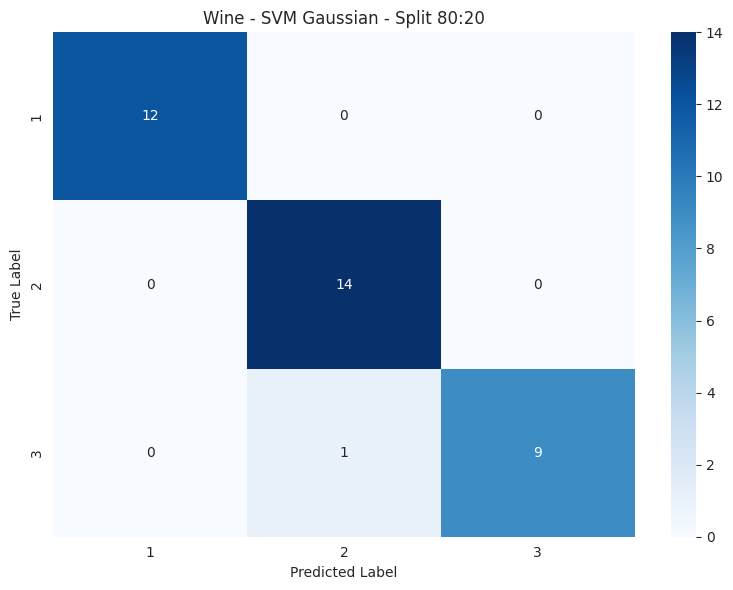

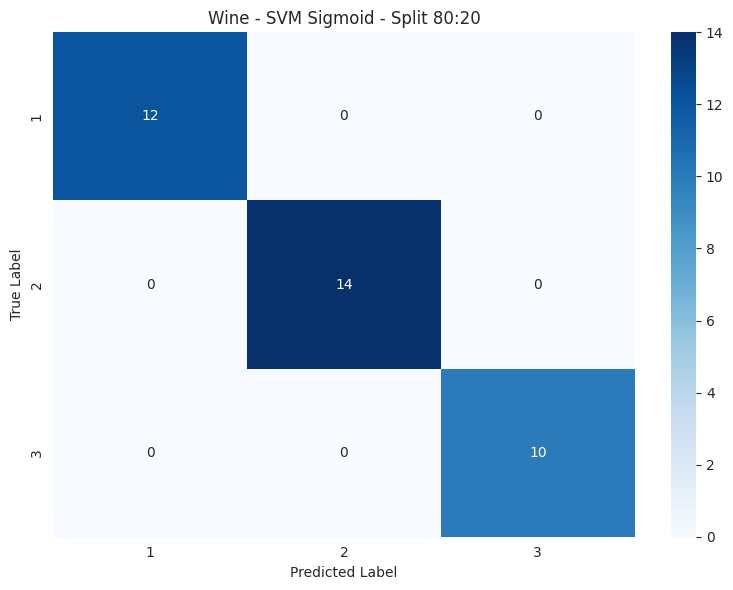

In [ ]:
class_names_wine = sorted(y_wine.unique())

for _, row in wine_svm_df.iterrows():

    plot_confusion_matrix(
        row["Confusion Matrix"],
        class_names_wine,
        f'Wine - {row["Classifier"]} - Split {row["Split"]}'
    )

For digits:

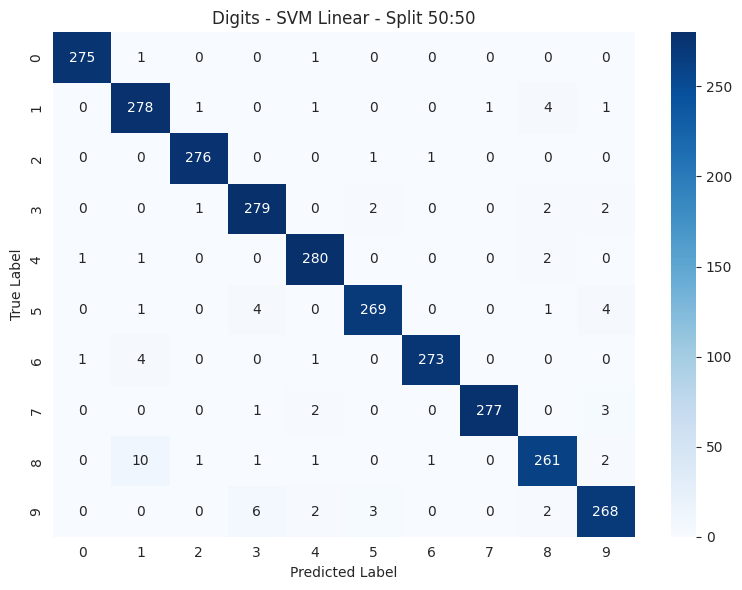

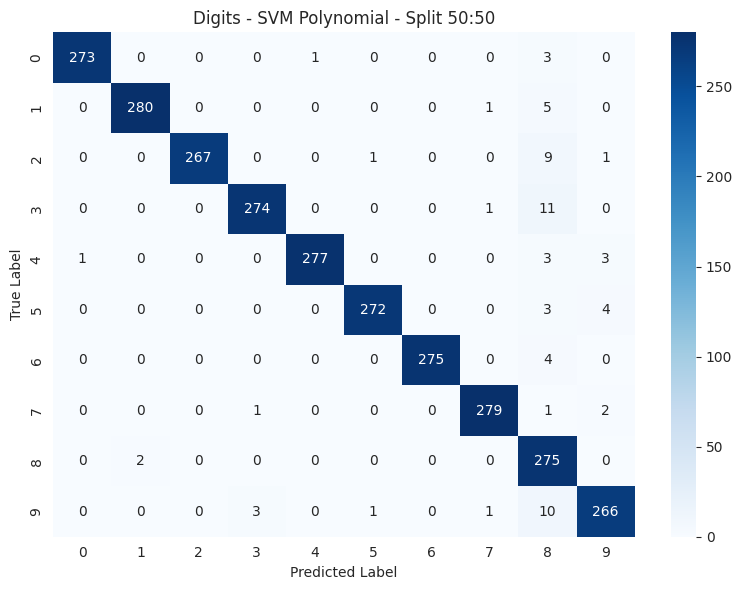

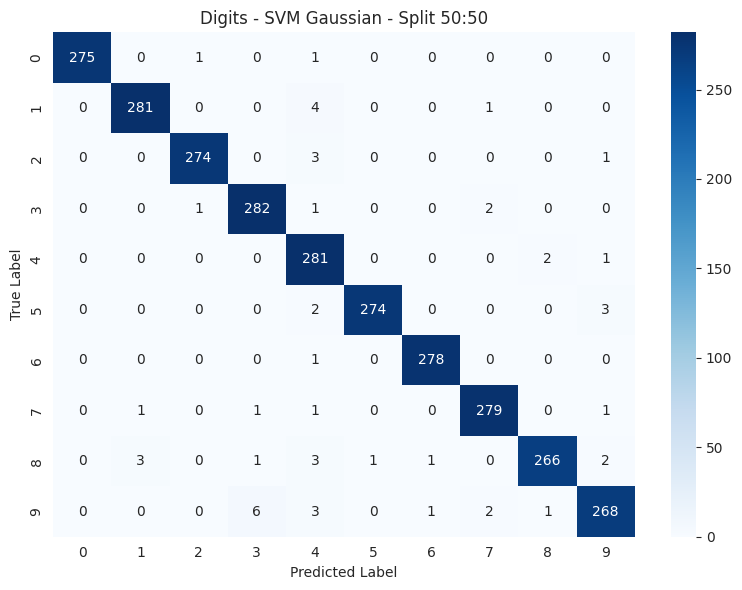

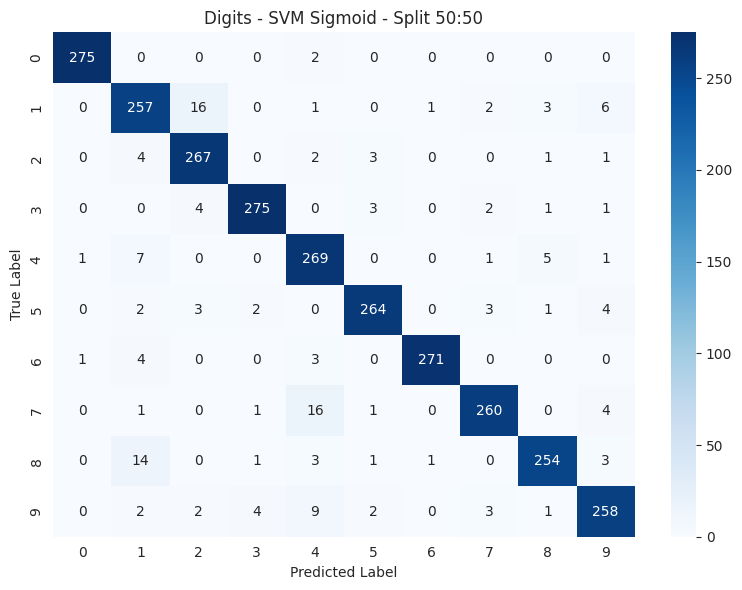

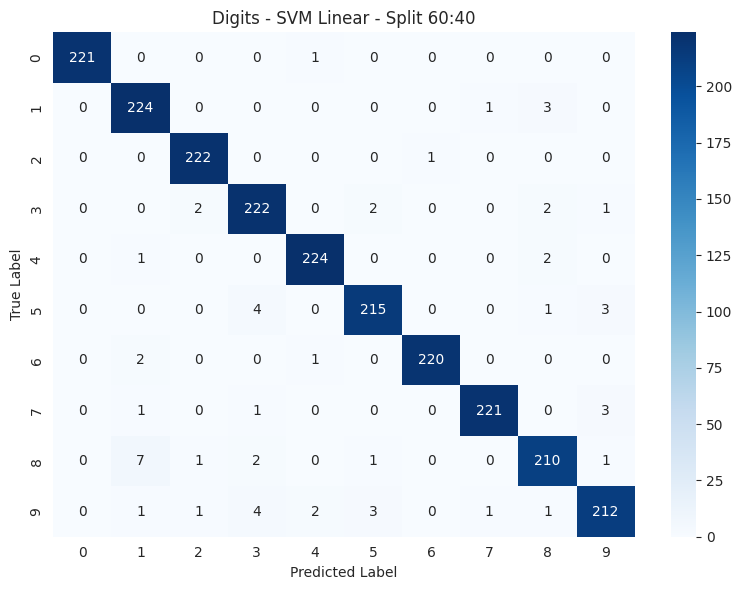

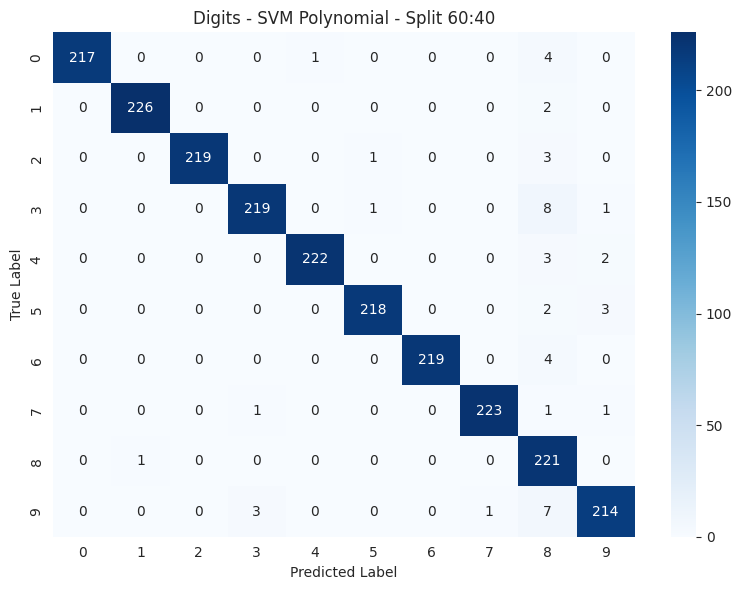

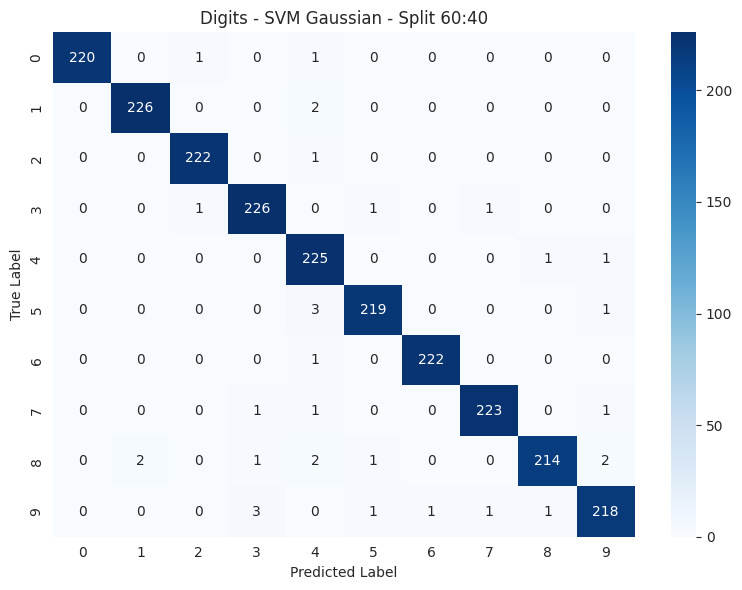

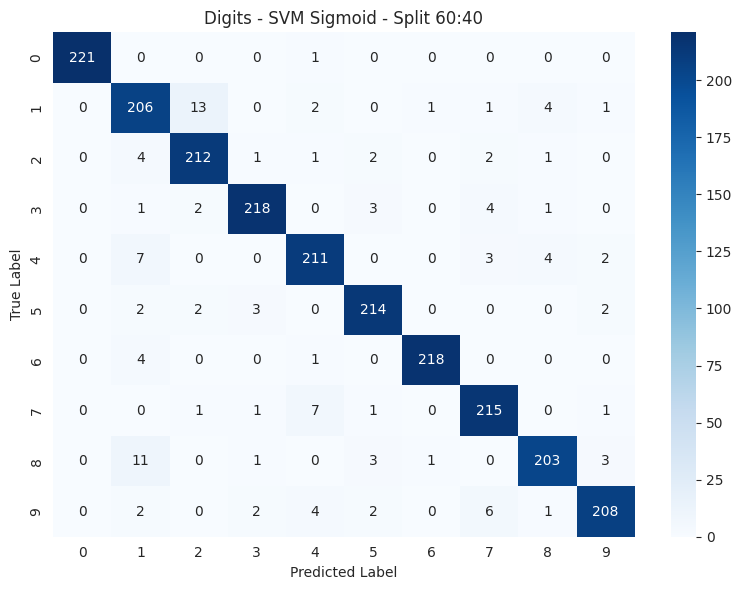

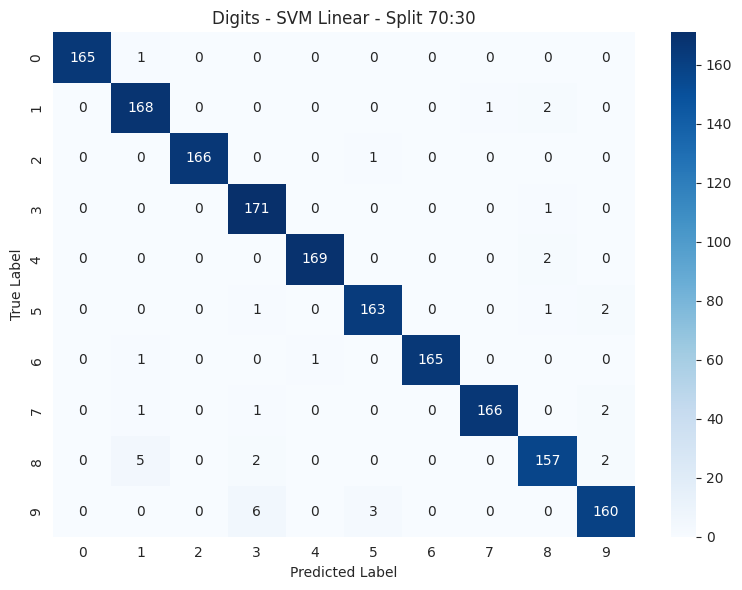

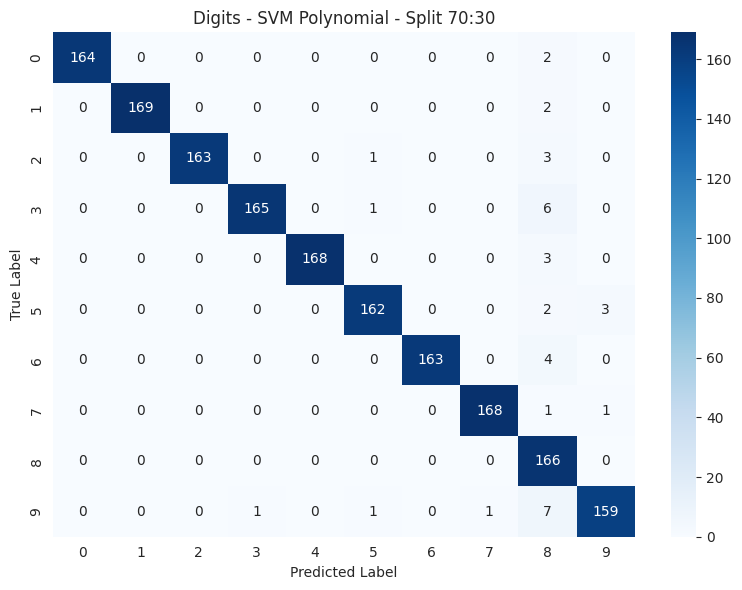

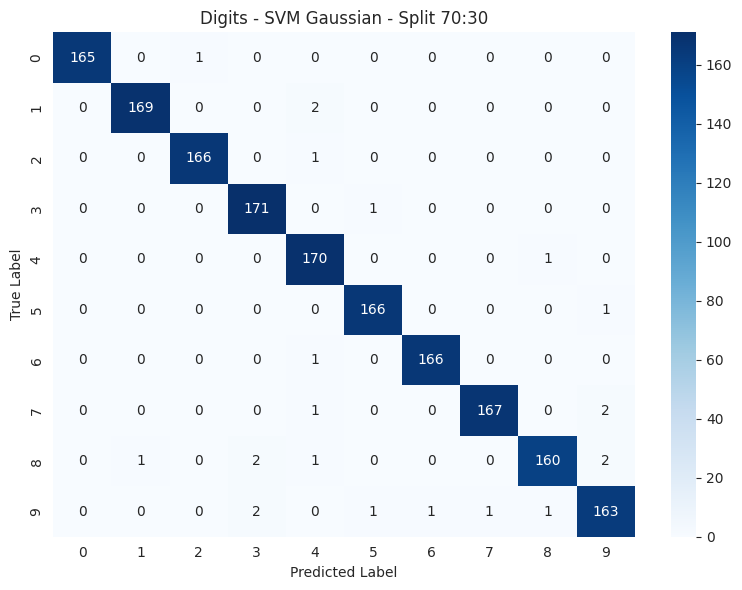

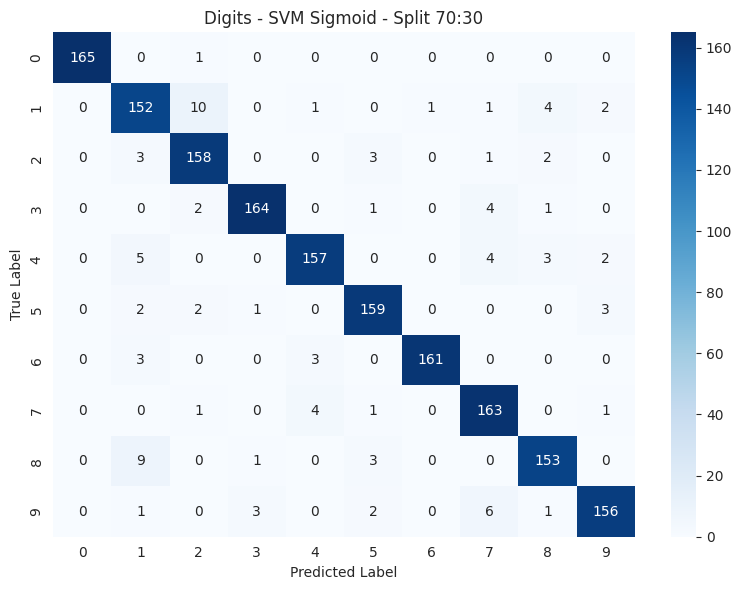

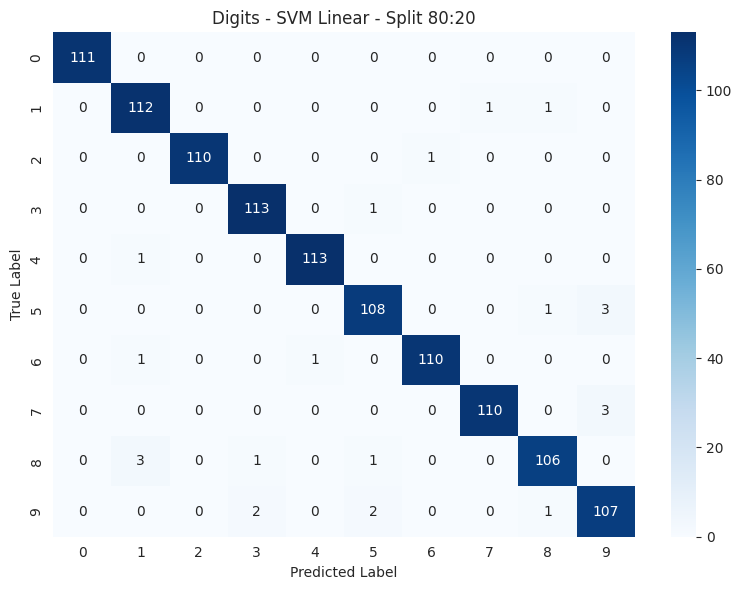

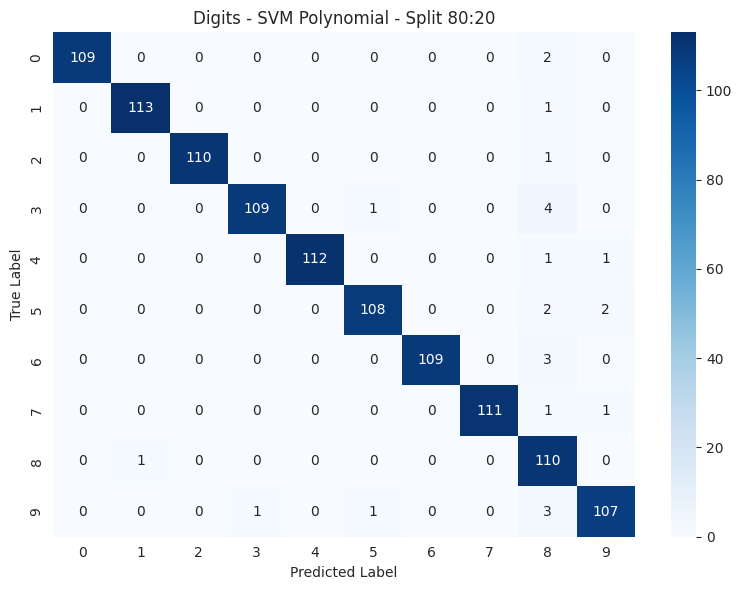

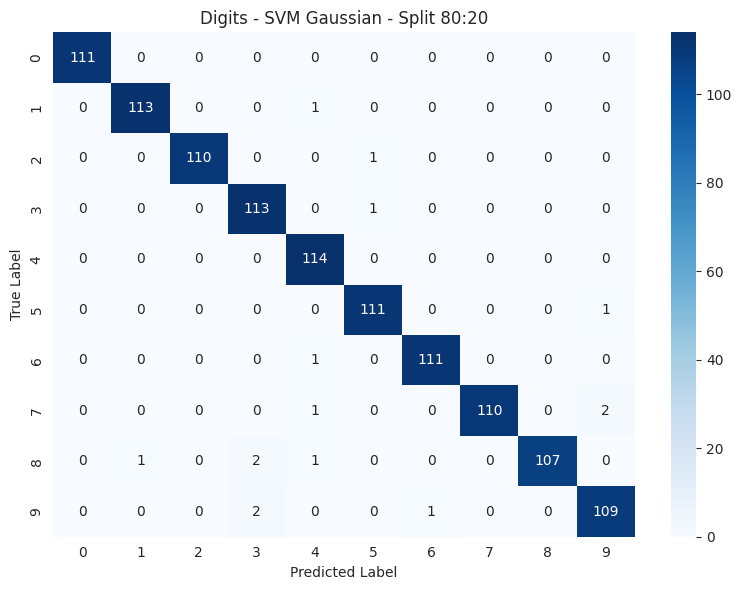

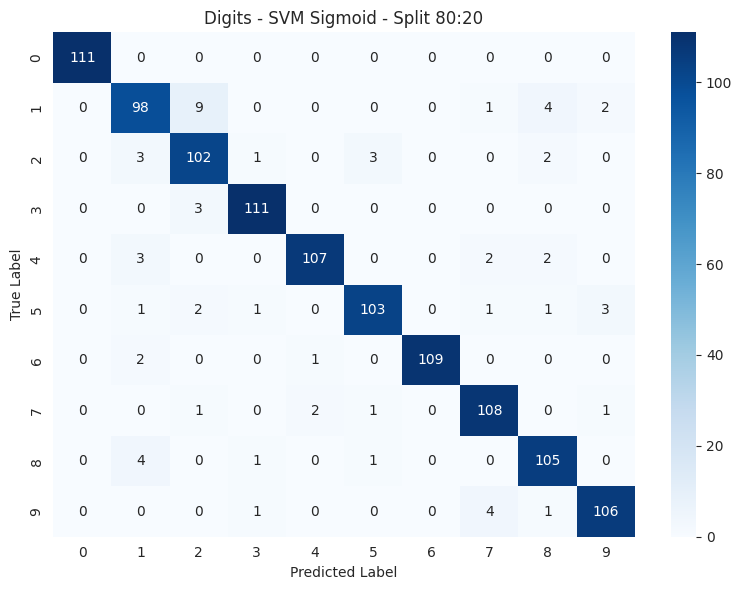

In [ ]:
class_names_digits = list(range(10))

for _, row in digits_svm_df.iterrows():

    plot_confusion_matrix(
        row["Confusion Matrix"],
        class_names_digits,
        f'Digits - {row["Classifier"]} - Split {row["Split"]}'
    )

Step 15: Basic MLP

In [ ]:
mlp_basic = MLPClassifier(
    hidden_layer_sizes=(100,),
    activation="relu",
    solver="sgd",
    learning_rate_init=0.001,
    momentum=0.9,
    max_iter=300,
    random_state=RANDOM_STATE
)

**Step 16: MLP on Wine**

In [ ]:
wine_mlp_results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X_wine,
        y_wine,
        test_size=test_size,
        stratify=y_wine,
        random_state=RANDOM_STATE
    )

    model = make_scaled_model(
        MLPClassifier(
            hidden_layer_sizes=(100,),
            activation="relu",
            solver="sgd",
            learning_rate_init=0.001,
            momentum=0.9,
            max_iter=500,
            random_state=RANDOM_STATE
        )
    )

    result = evaluate_model(
        model,
        X_train,
        X_test,
        y_train,
        y_test
    )

    wine_mlp_results.append({
        "Dataset": "Wine",
        "Split": split_name,
        "Classifier": "MLP",
        "Accuracy": result["Accuracy"],
        "Precision": result["Precision"],
        "Recall": result["Recall"],
        "F1 Score": result["F1 Score"],
        "Confusion Matrix": result["Confusion Matrix"],
        "Model": result["Model"]
    })

wine_mlp_df = pd.DataFrame(wine_mlp_results)

wine_mlp_df[
    ["Dataset", "Split", "Classifier",
     "Accuracy", "Precision", "Recall", "F1 Score"]
]

,Dataset,Split,Classifier,Accuracy,Precision,Recall,F1 Score
0,Wine,50:50,MLP,0.966292,0.966861,0.966292,0.966392
1,Wine,60:40,MLP,1.000000,1.000000,1.000000,1.000000
2,Wine,70:30,MLP,0.981481,0.982639,0.981481,0.981554
3,Wine,80:20,MLP,1.000000,1.000000,1.000000,1.000000


**Step 17: MLP on Digits**

In [ ]:
digits_mlp_results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X_digits,
        y_digits,
        test_size=test_size,
        stratify=y_digits,
        random_state=RANDOM_STATE
    )

    model = make_scaled_model(
        MLPClassifier(
            hidden_layer_sizes=(100,),
            activation="relu",
            solver="sgd",
            learning_rate_init=0.001,
            momentum=0.9,
            max_iter=500,
            random_state=RANDOM_STATE
        )
    )

    result = evaluate_model(
        model,
        X_train,
        X_test,
        y_train,
        y_test
    )

    digits_mlp_results.append({
        "Dataset": "Digits",
        "Split": split_name,
        "Classifier": "MLP",
        "Accuracy": result["Accuracy"],
        "Precision": result["Precision"],
        "Recall": result["Recall"],
        "F1 Score": result["F1 Score"],
        "Confusion Matrix": result["Confusion Matrix"],
        "Model": result["Model"]
    })

digits_mlp_df = pd.DataFrame(digits_mlp_results)

digits_mlp_df[
    ["Dataset", "Split", "Classifier",
     "Accuracy", "Precision", "Recall", "F1 Score"]
]

,Dataset,Split,Classifier,Accuracy,Precision,Recall,F1 Score
0,Digits,50:50,MLP,0.977580,0.977592,0.977580,0.977573
1,Digits,60:40,MLP,0.979093,0.979124,0.979093,0.979096
2,Digits,70:30,MLP,0.981020,0.981121,0.981020,0.981041
3,Digits,80:20,MLP,0.982206,0.982353,0.982206,0.982233


**Step 18: MLP training/loss curve**

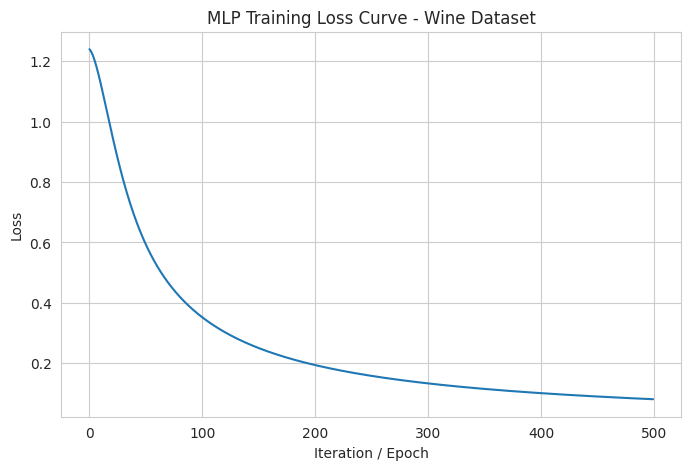

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_wine,
    y_wine,
    test_size=0.20,
    stratify=y_wine,
    random_state=RANDOM_STATE
)

mlp_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", MLPClassifier(
        hidden_layer_sizes=(100,),
        solver="sgd",
        learning_rate_init=0.001,
        momentum=0.9,
        max_iter=500,
        random_state=RANDOM_STATE
    ))
])

mlp_pipeline.fit(X_train, y_train)

mlp_model = mlp_pipeline.named_steps["model"]

plt.figure(figsize=(8, 5))
plt.plot(
    mlp_model.loss_curve_
)
plt.xlabel("Iteration / Epoch")
plt.ylabel("Loss")
plt.title("MLP Training Loss Curve - Wine Dataset")
plt.show()

Do the same for digits:

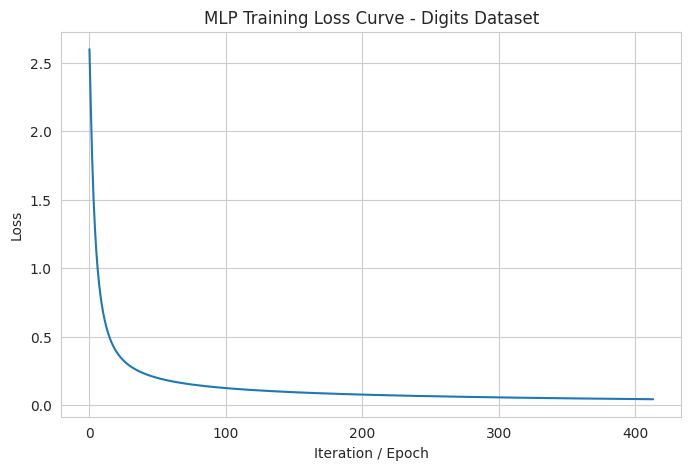

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_digits,
    y_digits,
    test_size=0.20,
    stratify=y_digits,
    random_state=RANDOM_STATE
)

mlp_pipeline_digits = Pipeline([
    ("scaler", StandardScaler()),
    ("model", MLPClassifier(
        hidden_layer_sizes=(100,),
        solver="sgd",
        learning_rate_init=0.001,
        momentum=0.9,
        max_iter=500,
        random_state=RANDOM_STATE
    ))
])

mlp_pipeline_digits.fit(X_train, y_train)

mlp_digits_model = mlp_pipeline_digits.named_steps["model"]

plt.figure(figsize=(8, 5))
plt.plot(mlp_digits_model.loss_curve_)
plt.xlabel("Iteration / Epoch")
plt.ylabel("Loss")
plt.title("MLP Training Loss Curve - Digits Dataset")
plt.show()

Add `%load_ext cudf.pandas` before importing pandas to speed up operations using GPU

In [ ]:
# %load_ext cudf.pandas
import pandas as pd
import numpy as np

# Randomly generated dataset of parking violations-
# Define the number of rows
num_rows = 1000000

states = ["NY", "NJ", "CA", "TX"]
violations = ["Double Parking", "Expired Meter", "No Parking",
              "Fire Hydrant", "Bus Stop"]
vehicle_types = ["SUBN", "SDN"]

# Create a date range
start_date = "2022-01-01"
end_date = "2022-12-31"
dates = pd.date_range(start=start_date, end=end_date, freq='D')

# Generate random data
data = {
    "Registration State": np.random.choice(states, size=num_rows),
    "Violation Description": np.random.choice(violations, size=num_rows),
    "Vehicle Body Type": np.random.choice(vehicle_types, size=num_rows),
    "Issue Date": np.random.choice(dates, size=num_rows),
    "Ticket Number": np.random.randint(1000000000, 9999999999, size=num_rows)
}

# Create a DataFrame
df = pd.DataFrame(data)

# Which parking violation is most commonly committed by vehicles from various U.S states?

(df[["Registration State", "Violation Description"]]  # get only these two columns
 .value_counts()  # get the count of offences per state and per type of offence
 .groupby("Registration State")  # group by state
 .head(1)  # get the first row in each group (the type of offence with the largest count)
 .sort_index()  # sort by state name
 .reset_index()
)

,Registration State,Violation Description,count
0,CA,Expired Meter,50140
1,NJ,Fire Hydrant,50258
2,NY,Bus Stop,50104
3,TX,Fire Hydrant,50491


**Step 19: Random Forest basic model**

In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

**Step 20: Random Forest on Wine**

In [ ]:
wine_rf_results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X_wine,
        y_wine,
        test_size=test_size,
        stratify=y_wine,
        random_state=RANDOM_STATE
    )

    model = RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    result = evaluate_model(
        model,
        X_train,
        X_test,
        y_train,
        y_test
    )

    wine_rf_results.append({
        "Dataset": "Wine",
        "Split": split_name,
        "Classifier": "Random Forest",
        "Accuracy": result["Accuracy"],
        "Precision": result["Precision"],
        "Recall": result["Recall"],
        "F1 Score": result["F1 Score"],
        "Confusion Matrix": result["Confusion Matrix"],
        "Model": result["Model"]
    })

wine_rf_df = pd.DataFrame(wine_rf_results)

wine_rf_df[
    ["Dataset", "Split", "Classifier",
     "Accuracy", "Precision", "Recall", "F1 Score"]
]

,Dataset,Split,Classifier,Accuracy,Precision,Recall,F1 Score
0,Wine,50:50,Random Forest,0.977528,0.978340,0.977528,0.977404
1,Wine,60:40,Random Forest,0.986111,0.986667,0.986111,0.986131
2,Wine,70:30,Random Forest,1.000000,1.000000,1.000000,1.000000
3,Wine,80:20,Random Forest,1.000000,1.000000,1.000000,1.000000


**Step 21: Random Forest on Digits**

In [ ]:
digits_rf_results = []

for split_name, test_size in splits.items():

    X_train, X_test, y_train, y_test = train_test_split(
        X_digits,
        y_digits,
        test_size=test_size,
        stratify=y_digits,
        random_state=RANDOM_STATE
    )

    model = RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    result = evaluate_model(
        model,
        X_train,
        X_test,
        y_train,
        y_test
    )

    digits_rf_results.append({
        "Dataset": "Digits",
        "Split": split_name,
        "Classifier": "Random Forest",
        "Accuracy": result["Accuracy"],
        "Precision": result["Precision"],
        "Recall": result["Recall"],
        "F1 Score": result["F1 Score"],
        "Confusion Matrix": result["Confusion Matrix"],
        "Model": result["Model"]
    })

digits_rf_df = pd.DataFrame(digits_rf_results)

digits_rf_df[
    ["Dataset", "Split", "Classifier",
     "Accuracy", "Precision", "Recall", "F1 Score"]
]

,Dataset,Split,Classifier,Accuracy,Precision,Recall,F1 Score
0,Digits,50:50,Random Forest,0.979359,0.979416,0.979359,0.979365
1,Digits,60:40,Random Forest,0.985765,0.985800,0.985765,0.985763
2,Digits,70:30,Random Forest,0.985172,0.985224,0.985172,0.985172
3,Digits,80:20,Random Forest,0.986655,0.986747,0.986655,0.986629


**Step 22: Combine all results**

Wine:

In [ ]:
wine_results = pd.concat([
    wine_svm_df,
    wine_mlp_df,
    wine_rf_df
], ignore_index=True)

wine_results[
    ["Dataset", "Split", "Classifier",
     "Accuracy", "Precision", "Recall", "F1 Score"]
]

,Dataset,Split,Classifier,Accuracy,Precision,Recall,F1 Score
0,Wine,50:50,SVM Linear,0.955056,0.955780,0.955056,0.954758
1,Wine,50:50,SVM Polynomial,0.853933,0.866553,0.853933,0.853971
2,Wine,50:50,SVM Gaussian,0.977528,0.977528,0.977528,0.977528
3,Wine,50:50,SVM Sigmoid,0.955056,0.956968,0.955056,0.955294
4,Wine,60:40,SVM Linear,0.958333,0.959974,0.958333,0.958336
5,Wine,60:40,SVM Polynomial,0.888889,0.902778,0.888889,0.889538
6,Wine,60:40,SVM Gaussian,0.986111,0.986574,0.986111,0.986041
7,Wine,60:40,SVM Sigmoid,1.000000,1.000000,1.000000,1.000000
8,Wine,70:30,SVM Linear,0.962963,0.963938,0.962963,0.962894
9,Wine,70:30,SVM Polynomial,0.907407,0.925214,0.907407,0.908485


Digits:

In [ ]:
digits_results = pd.concat([
    digits_svm_df,
    digits_mlp_df,
    digits_rf_df
], ignore_index=True)

digits_results[
    ["Dataset", "Split", "Classifier",
     "Accuracy", "Precision", "Recall", "F1 Score"]
]

,Dataset,Split,Classifier,Accuracy,Precision,Recall,F1 Score
0,Digits,50:50,SVM Linear,0.973665,0.973832,0.973665,0.973687
1,Digits,50:50,SVM Polynomial,0.974377,0.976763,0.974377,0.974915
2,Digits,50:50,SVM Gaussian,0.981495,0.981805,0.981495,0.981535
3,Digits,50:50,SVM Sigmoid,0.943060,0.944040,0.943060,0.943263
4,Digits,60:40,SVM Linear,0.974644,0.974765,0.974644,0.974638
5,Digits,60:40,SVM Polynomial,0.977758,0.979585,0.977758,0.978163
6,Digits,60:40,SVM Gaussian,0.985320,0.985475,0.985320,0.985335
7,Digits,60:40,SVM Sigmoid,0.945730,0.946305,0.945730,0.945877
8,Digits,70:30,SVM Linear,0.978648,0.978933,0.978648,0.978676
9,Digits,70:30,SVM Polynomial,0.976868,0.979458,0.976868,0.977428


**Step 23: Tune SVM**

Wine:

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_wine,
    y_wine,
    test_size=0.20,
    stratify=y_wine,
    random_state=RANDOM_STATE
)

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(probability=True))
])

svm_params = [
    {
        "svm__kernel": ["linear"],
        "svm__C": [0.1, 1, 10, 100]
    },
    {
        "svm__kernel": ["rbf"],
        "svm__C": [0.1, 1, 10, 100],
        "svm__gamma": ["scale", 0.01, 0.1, 1]
    },
    {
        "svm__kernel": ["poly"],
        "svm__C": [0.1, 1, 10],
        "svm__degree": [2, 3, 4]
    },
    {
        "svm__kernel": ["sigmoid"],
        "svm__C": [0.1, 1, 10]
    }
]

grid_svm = GridSearchCV(
    svm_pipeline,
    svm_params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_svm.fit(X_train, y_train)

print("Best parameters:")
print(grid_svm.best_params_)

print("\nBest CV Accuracy:")
print(grid_svm.best_score_)

Best parameters:
{'svm__C': 1, 'svm__gamma': 0.01, 'svm__kernel': 'rbf'}

Best CV Accuracy:
0.993103448275862


**Step 24: Evaluate tuned SVM**

Tuned SVM Results
------------------------
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


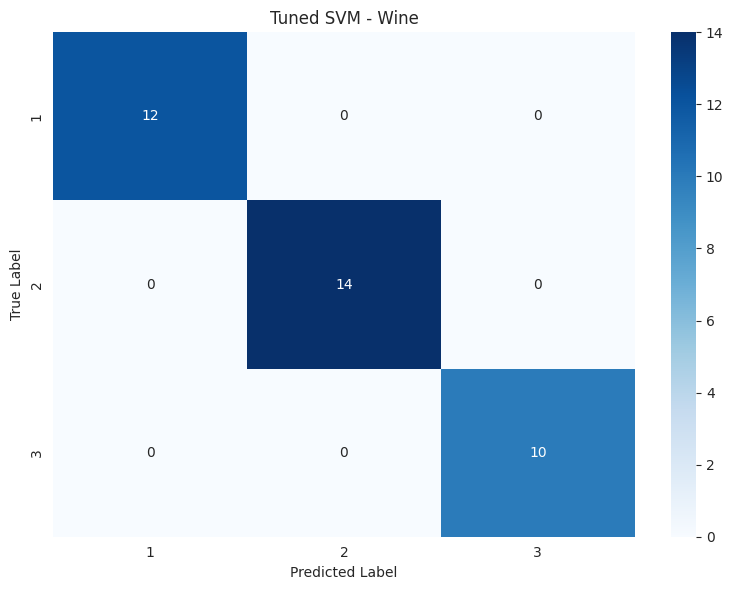

In [ ]:
y_pred = grid_svm.predict(X_test)

print("Tuned SVM Results")
print("------------------------")

print(
    "Accuracy:",
    accuracy_score(y_test, y_pred)
)

print(
    "Precision:",
    precision_score(
        y_test, y_pred,
        average="weighted"
    )
)

print(
    "Recall:",
    recall_score(
        y_test, y_pred,
        average="weighted"
    )
)

print(
    "F1 Score:",
    f1_score(
        y_test, y_pred,
        average="weighted"
    )
)

cm = confusion_matrix(y_test, y_pred)

plot_confusion_matrix(
    cm,
    class_names_wine,
    "Tuned SVM - Wine"
)

**Step 25: Tune MLP**

In [ ]:
mlp_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(
        solver="sgd",
        random_state=RANDOM_STATE
    ))
])

mlp_params = {
    "mlp__hidden_layer_sizes": [(50,), (100,), (100, 50)],
    "mlp__learning_rate_init": [0.001, 0.01, 0.1],
    "mlp__momentum": [0.5, 0.7, 0.9],
    "mlp__max_iter": [300, 500]
}

**Step 26: Tune MLP**

Try:

In [ ]:
mlp_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("mlp", MLPClassifier(
        solver="sgd",
        random_state=RANDOM_STATE
    ))
])

mlp_params = {
    "mlp__hidden_layer_sizes": [(50,), (100,), (100, 50)],
    "mlp__learning_rate_init": [0.001, 0.01, 0.1],
    "mlp__momentum": [0.5, 0.7, 0.9],
    "mlp__max_iter": [300, 500]
}

then:

In [ ]:
grid_mlp = GridSearchCV(
    mlp_pipeline,
    mlp_params,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

grid_mlp.fit(X_train, y_train)

print("Best MLP parameters:")
print(grid_mlp.best_params_)

print("\nBest CV Accuracy:")
print(grid_mlp.best_score_)

Best MLP parameters:
{'mlp__hidden_layer_sizes': (50,), 'mlp__learning_rate_init': 0.01, 'mlp__max_iter': 300, 'mlp__momentum': 0.9}

Best CV Accuracy:
0.9930555555555555


**Step 27: Tune Random Forest**

In [ ]:
rf = RandomForestClassifier(
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_params = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

then:

In [ ]:
grid_rf = GridSearchCV(
    rf,
    rf_params,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)

print("Best Random Forest parameters:")
print(grid_rf.best_params_)

print("\nBest CV Accuracy:")
print(grid_rf.best_score_)

Best Random Forest parameters:
{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}

Best CV Accuracy:
0.9862068965517242


**evaluate tuned random forest**

Tuned Random Forest Results
------------------------
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


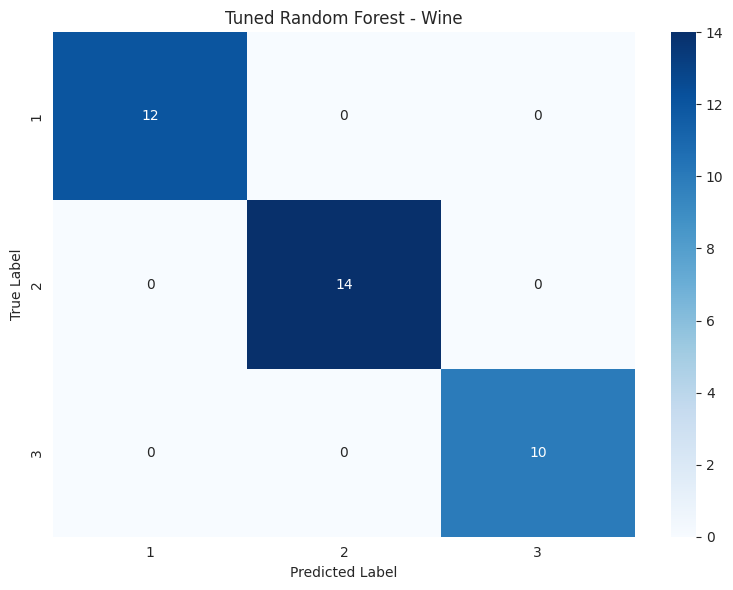

In [ ]:
y_pred = grid_rf.predict(X_test)

print("Tuned Random Forest Results")
print("------------------------")

print(
    "Accuracy:",
    accuracy_score(y_test, y_pred)
)

print(
    "Precision:",
    precision_score(
        y_test, y_pred,
        average="weighted"
    )
)

print(
    "Recall:",
    recall_score(
        y_test, y_pred,
        average="weighted"
    )
)

print(
    "F1 Score:",
    f1_score(
        y_test, y_pred,
        average="weighted"
    )
)

cm = confusion_matrix(y_test, y_pred)

plot_confusion_matrix(
    cm,
    class_names_wine,
    "Tuned Random Forest - Wine"
)

**evaluate tuned random forest on handwritten digits**

Best Random Forest parameters for Digits:
{'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}

Best CV Accuracy for Digits:
0.9799819075348557

Tuned Random Forest Results on Digits
-------------------------------------
Accuracy: 0.9857651245551602
Precision: 0.9858160886948233
Recall: 0.9857651245551602
F1 Score: 0.9857561482171892


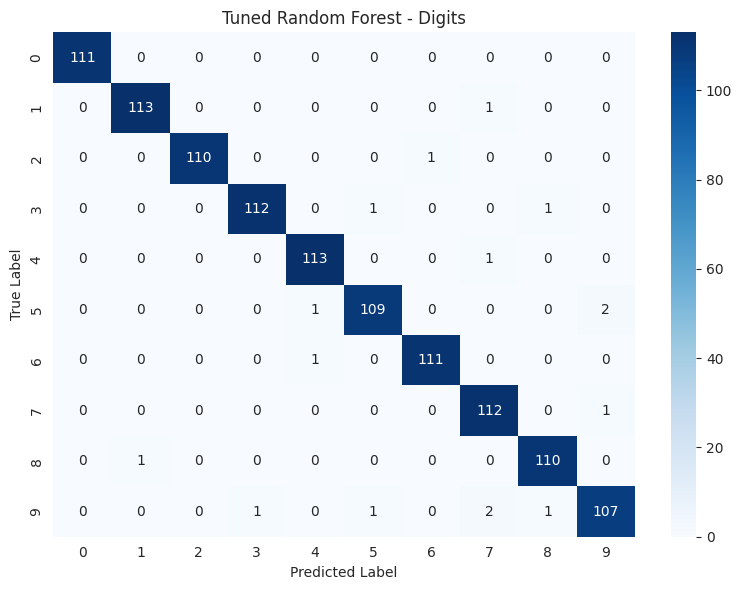

In [ ]:
X_train_digits, X_test_digits, y_train_digits, y_test_digits = train_test_split(
    X_digits,
    y_digits,
    test_size=0.20,
    stratify=y_digits,
    random_state=RANDOM_STATE
)

rf_digits = RandomForestClassifier(
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_params_digits = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", "log2"]
}

grid_rf_digits = GridSearchCV(
    rf_digits,
    rf_params_digits,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

grid_rf_digits.fit(X_train_digits, y_train_digits)

print("Best Random Forest parameters for Digits:")
print(grid_rf_digits.best_params_)

print("\nBest CV Accuracy for Digits:")
print(grid_rf_digits.best_score_)

y_pred_digits = grid_rf_digits.predict(X_test_digits)

print("\nTuned Random Forest Results on Digits")
print("-------------------------------------")

print(
    "Accuracy:",
    accuracy_score(y_test_digits, y_pred_digits)
)

print(
    "Precision:",
    precision_score(
        y_test_digits, y_pred_digits,
        average="weighted"
    )
)

print(
    "Recall:",
    recall_score(
        y_test_digits, y_pred_digits,
        average="weighted"
    )
)

print(
    "F1 Score:",
    f1_score(
        y_test_digits, y_pred_digits,
        average="weighted"
    )
)

cm_digits = confusion_matrix(y_test_digits, y_pred_digits)

plot_confusion_matrix(
    cm_digits,
    class_names_digits,
    "Tuned Random Forest - Digits"
)

**STEP 28 — ROC function**

In [ ]:
def plot_multiclass_roc(model, X_test, y_test, title):

    classes = np.unique(y_test)

    y_test_bin = label_binarize(
        y_test,
        classes=classes
    )

    y_score = model.predict_proba(X_test)

    plt.figure(figsize=(9, 7))

    for i, cls in enumerate(classes):

        fpr, tpr, _ = roc_curve(
            y_test_bin[:, i],
            y_score[:, i]
        )

        roc_auc = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            label=f"Class {cls} (AUC = {roc_auc:.3f})"
        )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")

    plt.title(title)

    plt.legend()
    plt.grid(True)

    plt.show()

**STEP 29 — ROC for SVM**

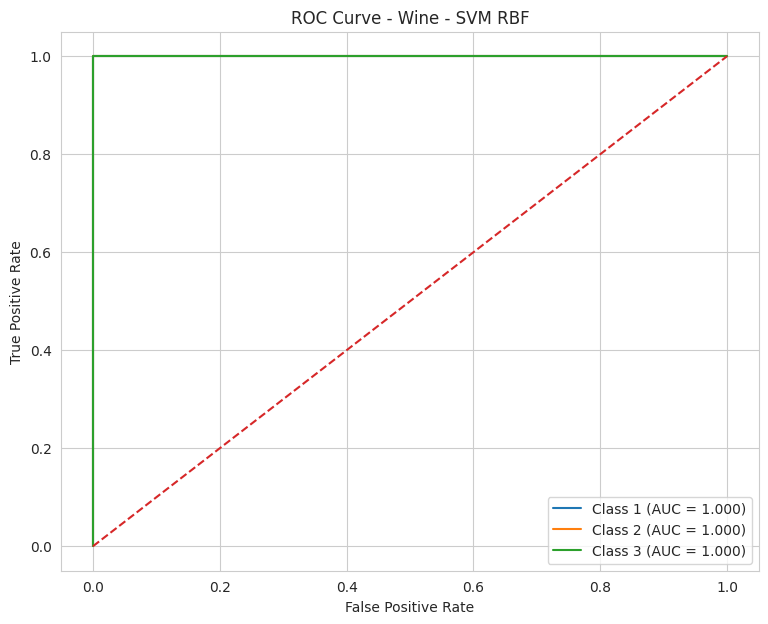

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_wine,
    y_wine,
    test_size=0.20,
    stratify=y_wine,
    random_state=RANDOM_STATE
)

svm_rbf = make_scaled_model(
    SVC(
        kernel="rbf",
        probability=True,
        random_state=RANDOM_STATE
    )
)

svm_rbf.fit(X_train, y_train)

plot_multiclass_roc(
    svm_rbf,
    X_test,
    y_test,
    "ROC Curve - Wine - SVM RBF"
)

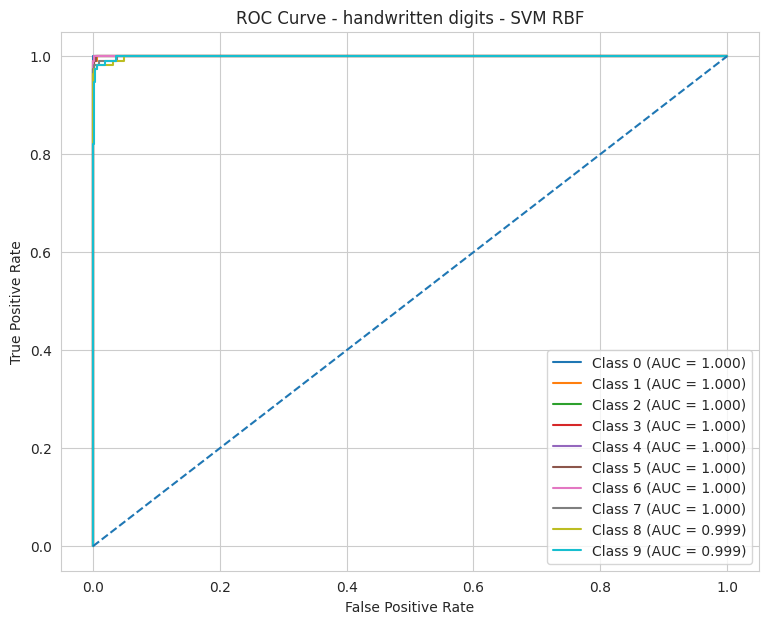

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_digits,
    y_digits,
    test_size=0.20,
    stratify=y_digits,
    random_state=RANDOM_STATE
)

svm_rbf = make_scaled_model(
    SVC(
        kernel="rbf",
        probability=True,
        random_state=RANDOM_STATE
    )
)

svm_rbf.fit(X_train, y_train)

plot_multiclass_roc(
    svm_rbf,
    X_test,
    y_test,
    "ROC Curve - handwritten digits - SVM RBF"
)

**STEP 30 — ROC for MLP**

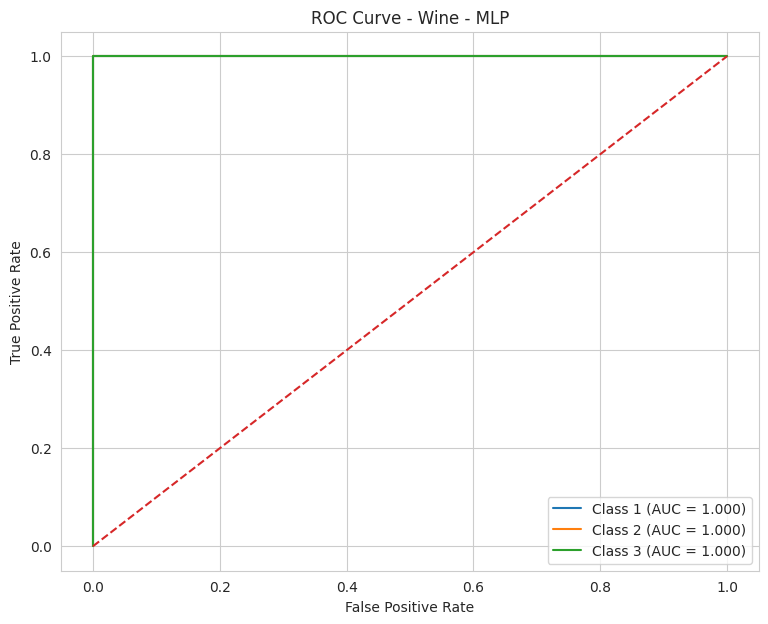

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_wine,
    y_wine,
    test_size=0.20,
    stratify=y_wine,
    random_state=RANDOM_STATE
)

mlp_roc = make_scaled_model(
    MLPClassifier(
        hidden_layer_sizes=(100,),
        solver="sgd",
        learning_rate_init=0.001,
        momentum=0.9,
        max_iter=500,
        random_state=RANDOM_STATE
    )
)

mlp_roc.fit(X_train, y_train)

plot_multiclass_roc(
    mlp_roc,
    X_test,
    y_test,
    "ROC Curve - Wine - MLP"
)

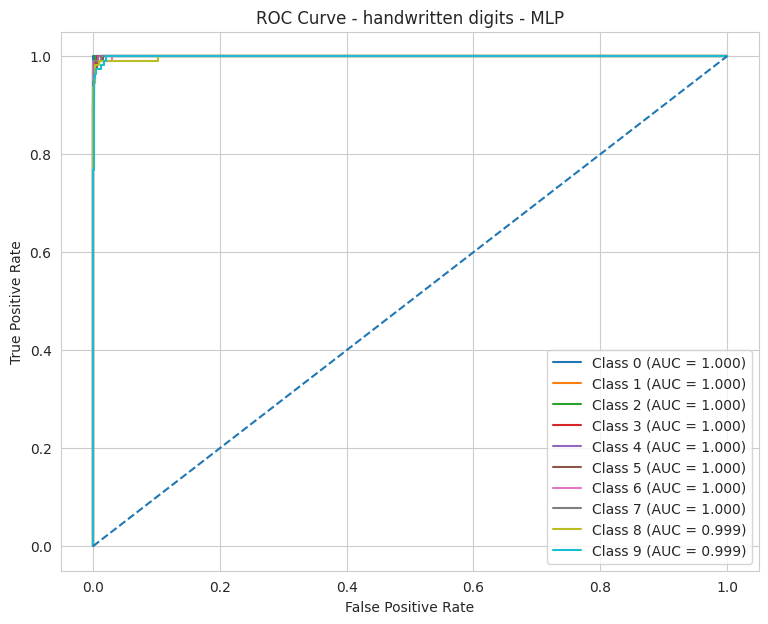

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_digits,
    y_digits,
    test_size=0.20,
    stratify=y_digits,
    random_state=RANDOM_STATE
)

mlp_roc = make_scaled_model(
    MLPClassifier(
        hidden_layer_sizes=(100,),
        solver="sgd",
        learning_rate_init=0.001,
        momentum=0.9,
        max_iter=500,
        random_state=RANDOM_STATE
    )
)

mlp_roc.fit(X_train, y_train)

plot_multiclass_roc(
    mlp_roc,
    X_test,
    y_test,
    "ROC Curve - handwritten digits - MLP"
)

**STEP 31 — ROC for Random Forest**

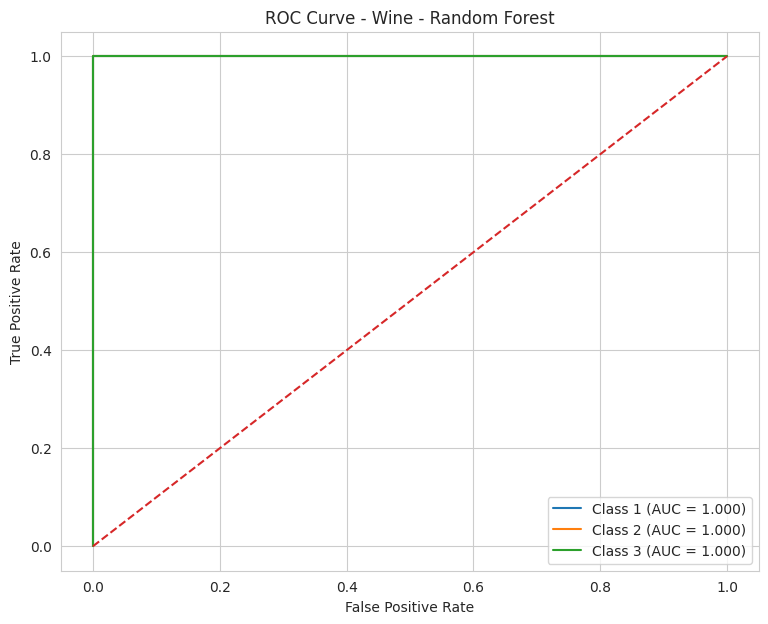

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_wine,
    y_wine,
    test_size=0.20,
    stratify=y_wine,
    random_state=RANDOM_STATE
)

rf_roc = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_roc.fit(X_train, y_train)

plot_multiclass_roc(
    rf_roc,
    X_test,
    y_test,
    "ROC Curve - Wine - Random Forest"
)

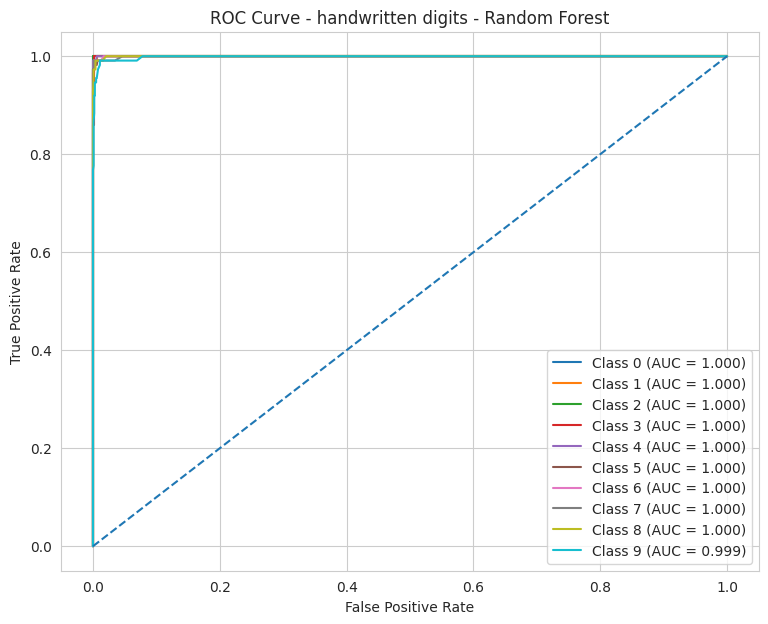

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_digits,
    y_digits,
    test_size=0.20,
    stratify=y_digits,
    random_state=RANDOM_STATE
)

rf_roc = RandomForestClassifier(
    n_estimators=100,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_roc.fit(X_train, y_train)

plot_multiclass_roc(
    rf_roc,
    X_test,
    y_test,
    "ROC Curve - handwritten digits - Random Forest"
)

**STEP 32 — Determine PCA components**

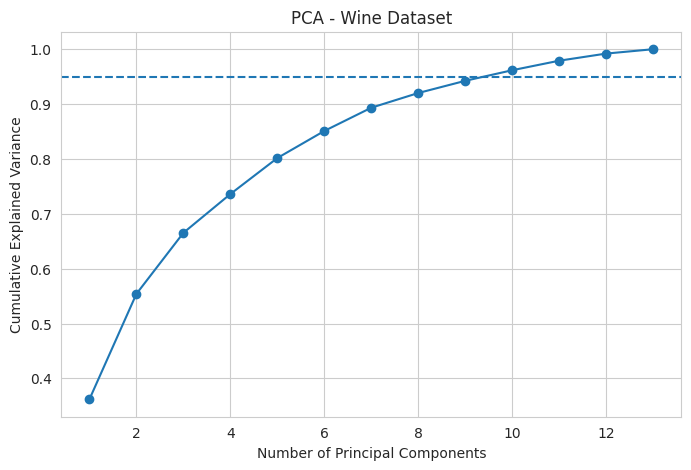

In [ ]:
scaler = StandardScaler()

X_wine_scaled = scaler.fit_transform(X_wine)

pca_full = PCA()

X_wine_pca_full = pca_full.fit_transform(X_wine_scaled)

cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.95,
    linestyle="--"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Wine Dataset")

plt.show()

**STEP 33 — Automatically select 95% PCA components**

In [ ]:
pca_wine = PCA(
    n_components=0.95
)

X_wine_pca = pca_wine.fit_transform(
    X_wine_scaled
)

print("Original number of features:", X_wine.shape[1])
print("PCA components:", X_wine_pca.shape[1])

Original number of features: 13
PCA components: 10


**STEP 34 — PCA for Digits**

In [ ]:
scaler_digits = StandardScaler()

X_digits_scaled = scaler_digits.fit_transform(
    X_digits
)

pca_digits = PCA(
    n_components=0.95
)

X_digits_pca = pca_digits.fit_transform(
    X_digits_scaled
)

print("Original features:", X_digits.shape[1])
print("PCA components:", X_digits_pca.shape[1])

Original features: 64
PCA components: 42


**STEP 35 — SVM after PCA**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_wine_pca,
    y_wine,
    test_size=0.20,
    stratify=y_wine,
    random_state=RANDOM_STATE
)

pca_svm = SVC(
    kernel="rbf",
    probability=True,
    random_state=RANDOM_STATE
)

pca_svm.fit(X_train, y_train)

y_pred = pca_svm.predict(X_test)

print("PCA + SVM")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(
    "Precision:",
    precision_score(y_test, y_pred, average="weighted")
)
print(
    "Recall:",
    recall_score(y_test, y_pred, average="weighted")
)
print(
    "F1:",
    f1_score(y_test, y_pred, average="weighted")
)

PCA + SVM
Accuracy: 0.9722222222222222
Precision: 0.974074074074074
Recall: 0.9722222222222222
F1: 0.9719701552732407


**STEP 36 — MLP after PCA**


In [ ]:
pca_mlp = MLPClassifier(
    hidden_layer_sizes=(100,),
    solver="sgd",
    learning_rate_init=0.001,
    momentum=0.9,
    max_iter=500,
    random_state=RANDOM_STATE
)

pca_mlp.fit(X_train, y_train)

y_pred = pca_mlp.predict(X_test)

print("PCA + MLP")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(
    "Precision:",
    precision_score(y_test, y_pred, average="weighted")
)
print(
    "Recall:",
    recall_score(y_test, y_pred, average="weighted")
)
print(
    "F1:",
    f1_score(y_test, y_pred, average="weighted")
)

PCA + MLP
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1: 1.0


**STEP 37 — Random Forest after PCA**

In [ ]:
pca_rf = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

pca_rf.fit(X_train, y_train)

y_pred = pca_rf.predict(X_test)

print("PCA + Random Forest")
print("Accuracy:", accuracy_score(y_test, y_pred))
print(
    "Precision:",
    precision_score(y_test, y_pred, average="weighted")
)
print(
    "Recall:",
    recall_score(y_test, y_pred, average="weighted")
)
print(
    "F1:",
    f1_score(y_test, y_pred, average="weighted")
)

PCA + Random Forest
Accuracy: 0.9444444444444444
Precision: 0.9444444444444444
Recall: 0.9444444444444444
F1: 0.9444444444444444


**STEP 38 — PCA confusion matrix**

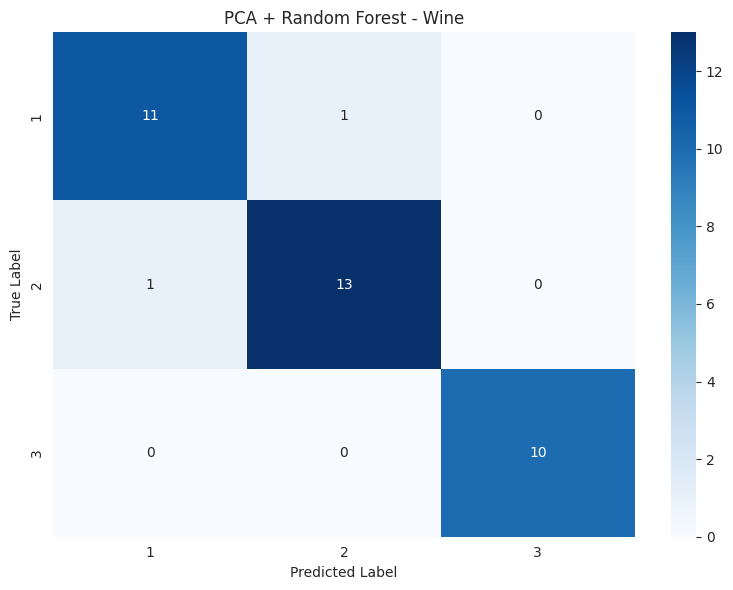

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plot_confusion_matrix(
    cm,
    class_names_wine,
    "PCA + Random Forest - Wine"
)

**PART G — PCA + all classifiers for both datasets**

In [ ]:
def run_pca_classifiers(X, y, dataset_name):

    results = []

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.20,
        stratify=y,
        random_state=RANDOM_STATE
    )

    models = {

        "PCA + SVM": Pipeline([
            ("scaler", StandardScaler()),
            ("pca", PCA(n_components=0.95)),
            ("model", SVC(
                kernel="rbf",
                probability=True,
                random_state=RANDOM_STATE
            ))
        ]),

        "PCA + MLP": Pipeline([
            ("scaler", StandardScaler()),
            ("pca", PCA(n_components=0.95)),
            ("model", MLPClassifier(
                hidden_layer_sizes=(100,),
                solver="sgd",
                learning_rate_init=0.001,
                momentum=0.9,
                max_iter=500,
                random_state=RANDOM_STATE
            ))
        ]),

        "PCA + Random Forest": Pipeline([
            ("scaler", StandardScaler()),
            ("pca", PCA(n_components=0.95)),
            ("model", RandomForestClassifier(
                n_estimators=200,
                random_state=RANDOM_STATE,
                n_jobs=-1
            ))
        ])
    }

    for name, model in models.items():

        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)

        results.append({
            "Dataset": dataset_name,
            "Classifier": name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(
                y_test,
                y_pred,
                average="weighted",
                zero_division=0
            ),
            "Recall": recall_score(
                y_test,
                y_pred,
                average="weighted",
                zero_division=0
            ),
            "F1 Score": f1_score(
                y_test,
                y_pred,
                average="weighted",
                zero_division=0
            ),
            "Confusion Matrix": confusion_matrix(
                y_test,
                y_pred
            )
        })

    return pd.DataFrame(results)

Run:

In [ ]:
pca_wine_results = run_pca_classifiers(
    X_wine,
    y_wine,
    "Wine"
)

pca_digits_results = run_pca_classifiers(
    X_digits,
    y_digits,
    "Digits"
)

**STEP 39 — Final PCA table**

In [ ]:
pca_results = pd.concat([
    pca_wine_results,
    pca_digits_results
], ignore_index=True)

display(
    pca_results[
        [
            "Dataset",
            "Classifier",
            "Accuracy",
            "Precision",
            "Recall",
            "F1 Score"
        ]
    ]
)

,Dataset,Classifier,Accuracy,Precision,Recall,F1 Score
0,Wine,PCA + SVM,0.972222,0.974074,0.972222,0.971970
1,Wine,PCA + MLP,0.972222,0.974074,0.972222,0.971970
2,Wine,PCA + Random Forest,0.944444,0.944444,0.944444,0.944444
3,Digits,PCA + SVM,0.986655,0.986882,0.986655,0.986668
4,Digits,PCA + MLP,0.976868,0.977071,0.976868,0.976869
5,Digits,PCA + Random Forest,0.970641,0.971062,0.970641,0.970697


**PART H — FINAL PERFORMANCE COMPARISON**

In [ ]:
final_table = pd.concat([
    wine_results[
        [
            "Dataset",
            "Split",
            "Classifier",
            "Accuracy",
            "Precision",
            "Recall",
            "F1 Score"
        ]
    ],

    digits_results[
        [
            "Dataset",
            "Split",
            "Classifier",
            "Accuracy",
            "Precision",
            "Recall",
            "F1 Score"
        ]
    ]
], ignore_index=True)

display(final_table)

,Dataset,Split,Classifier,Accuracy,Precision,Recall,F1 Score
0,Wine,50:50,SVM Linear,0.955056,0.955780,0.955056,0.954758
1,Wine,50:50,SVM Polynomial,0.853933,0.866553,0.853933,0.853971
2,Wine,50:50,SVM Gaussian,0.977528,0.977528,0.977528,0.977528
3,Wine,50:50,SVM Sigmoid,0.955056,0.956968,0.955056,0.955294
4,Wine,60:40,SVM Linear,0.958333,0.959974,0.958333,0.958336
5,Wine,60:40,SVM Polynomial,0.888889,0.902778,0.888889,0.889538
6,Wine,60:40,SVM Gaussian,0.986111,0.986574,0.986111,0.986041
7,Wine,60:40,SVM Sigmoid,1.000000,1.000000,1.000000,1.000000
8,Wine,70:30,SVM Linear,0.962963,0.963938,0.962963,0.962894
9,Wine,70:30,SVM Polynomial,0.907407,0.925214,0.907407,0.908485


**STEP 40 — Show percentages**

In [ ]:
comparison_table = final_table.copy()

for col in [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]:
    comparison_table[col] = (
        comparison_table[col] * 100
    ).round(2)

display(comparison_table)

,Dataset,Split,Classifier,Accuracy,Precision,Recall,F1 Score
0,Wine,50:50,SVM Linear,95.51,95.58,95.51,95.48
1,Wine,50:50,SVM Polynomial,85.39,86.66,85.39,85.40
2,Wine,50:50,SVM Gaussian,97.75,97.75,97.75,97.75
3,Wine,50:50,SVM Sigmoid,95.51,95.70,95.51,95.53
4,Wine,60:40,SVM Linear,95.83,96.00,95.83,95.83
5,Wine,60:40,SVM Polynomial,88.89,90.28,88.89,88.95
6,Wine,60:40,SVM Gaussian,98.61,98.66,98.61,98.60
7,Wine,60:40,SVM Sigmoid,100.00,100.00,100.00,100.00
8,Wine,70:30,SVM Linear,96.30,96.39,96.30,96.29
9,Wine,70:30,SVM Polynomial,90.74,92.52,90.74,90.85


**STEP 41 — Find the best model**

In [ ]:
best_models = comparison_table.sort_values(
    "Accuracy",
    ascending=False
)

display(best_models.head(10))

,Dataset,Split,Classifier,Accuracy,Precision,Recall,F1 Score
7,Wine,60:40,SVM Sigmoid,100.00,100.00,100.00,100.00
15,Wine,80:20,SVM Sigmoid,100.00,100.00,100.00,100.00
19,Wine,80:20,MLP,100.00,100.00,100.00,100.00
17,Wine,60:40,MLP,100.00,100.00,100.00,100.00
23,Wine,80:20,Random Forest,100.00,100.00,100.00,100.00
22,Wine,70:30,Random Forest,100.00,100.00,100.00,100.00
38,Digits,80:20,SVM Gaussian,98.67,98.69,98.67,98.67
47,Digits,80:20,Random Forest,98.67,98.67,98.67,98.66
34,Digits,70:30,SVM Gaussian,98.64,98.64,98.64,98.64
21,Wine,60:40,Random Forest,98.61,98.67,98.61,98.61


**STEP 42 — Compare classifiers graphically**

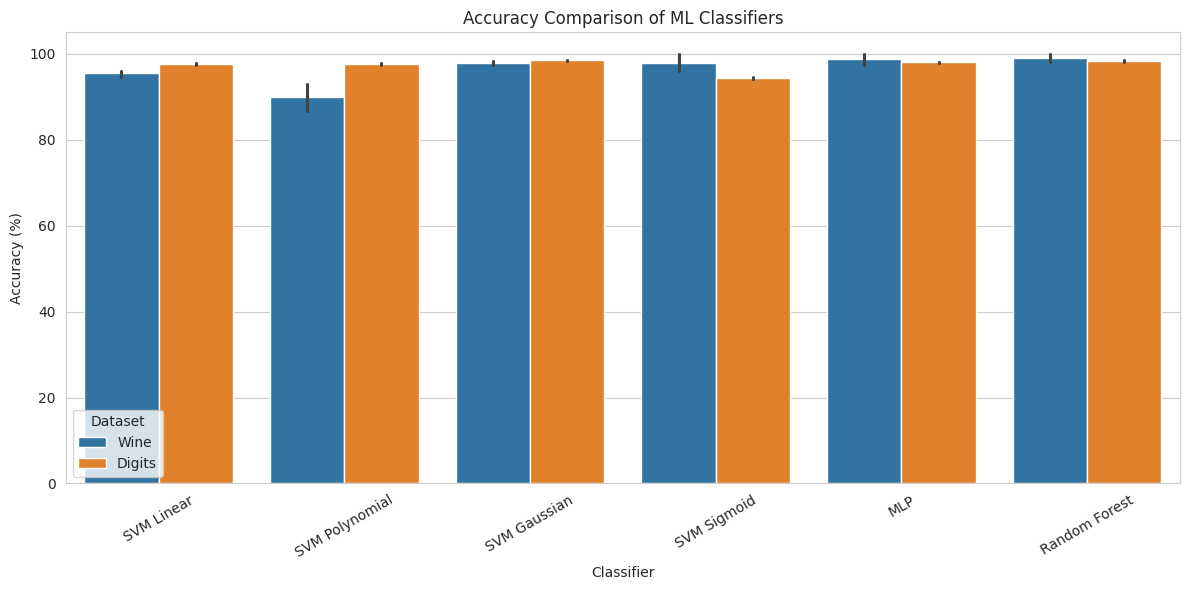

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison_table,
    x="Classifier",
    y="Accuracy",
    hue="Dataset"
)

plt.ylabel("Accuracy (%)")
plt.xlabel("Classifier")
plt.title("Accuracy Comparison of ML Classifiers")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**STEP 43 — Compare train/test split**

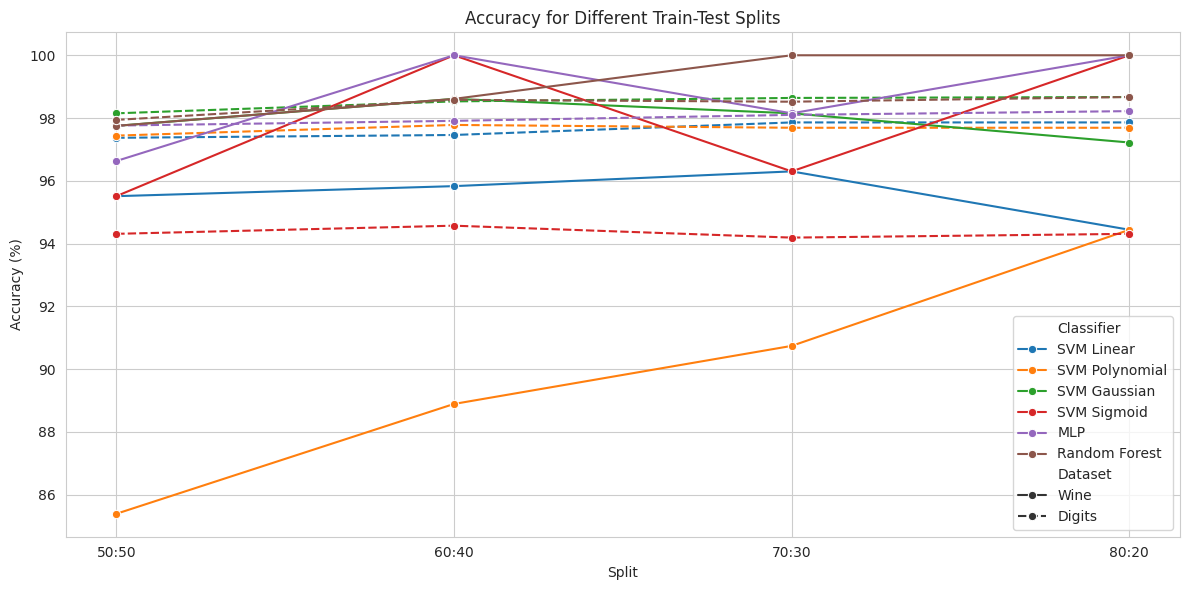

In [ ]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=comparison_table,
    x="Split",
    y="Accuracy",
    hue="Classifier",
    style="Dataset",
    marker="o"
)

plt.ylabel("Accuracy (%)")
plt.title("Accuracy for Different Train-Test Splits")
plt.tight_layout()
plt.show()

**PART I — TRAINING CURVES**

**STEP 44 — Random Forest training curve**

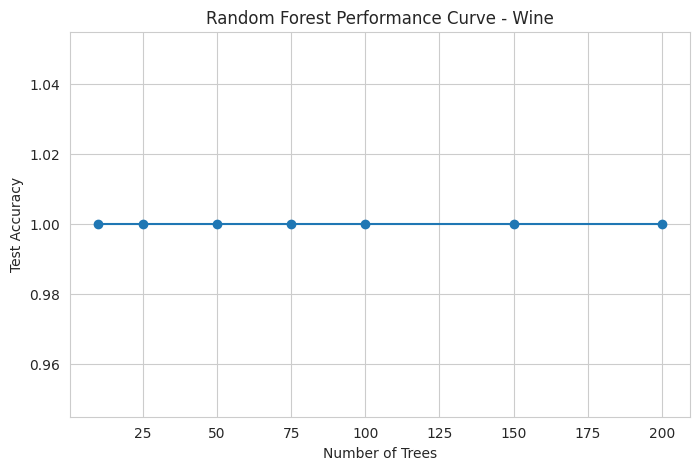

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_wine,
    y_wine,
    test_size=0.20,
    stratify=y_wine,
    random_state=RANDOM_STATE
)

n_trees = [10, 25, 50, 75, 100, 150, 200]

accuracies = []

for n in n_trees:

    rf = RandomForestClassifier(
        n_estimators=n,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)

    y_pred = rf.predict(X_test)

    accuracies.append(
        accuracy_score(y_test, y_pred)
    )

plt.figure(figsize=(8, 5))

plt.plot(
    n_trees,
    accuracies,
    marker="o"
)

plt.xlabel("Number of Trees")
plt.ylabel("Test Accuracy")
plt.title("Random Forest Performance Curve - Wine")

plt.show()

**STEP 45 — SVM parameter performance curve**

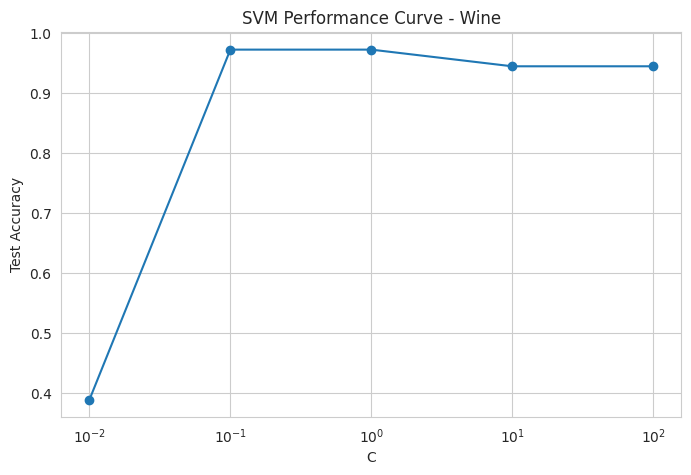

In [ ]:
C_values = [0.01, 0.1, 1, 10, 100]

svm_accuracy = []

X_train, X_test, y_train, y_test = train_test_split(
    X_wine,
    y_wine,
    test_size=0.20,
    stratify=y_wine,
    random_state=RANDOM_STATE
)

for C in C_values:

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(
            kernel="rbf",
            C=C,
            probability=True,
            random_state=RANDOM_STATE
        ))
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    svm_accuracy.append(
        accuracy_score(y_test, y_pred)
    )

plt.figure(figsize=(8, 5))

plt.plot(
    C_values,
    svm_accuracy,
    marker="o"
)

plt.xscale("log")

plt.xlabel("C")
plt.ylabel("Test Accuracy")
plt.title("SVM Performance Curve - Wine")

plt.show()

**STEP 46 — Save results to CSV**

In [ ]:
comparison_table.to_csv(
    "classification_results.csv",
    index=False
)

pca_results.to_csv(
    "pca_results.csv",
    index=False
)

print("Results saved successfully.")

from google.colab import files

files.download("classification_results.csv")

Results saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**STEP 47 — Save graphs**

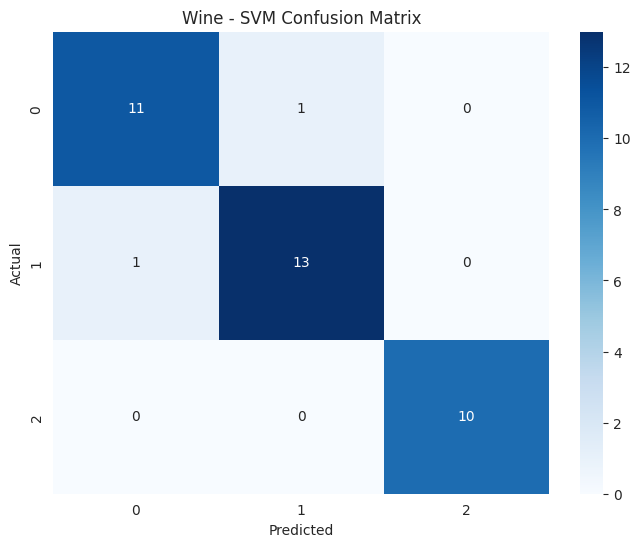

In [ ]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Wine - SVM Confusion Matrix")

plt.savefig(
    "wine_svm_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**overall result comparison**

In [ ]:
import pandas as pd

# Define best parameters for each model/dataset combination
best_params_dict = {
    ("Wine", "SVM"): "{'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}", # From grid_svm.best_params_
    ("Wine", "MLP"): "{'hidden_layer_sizes': (50,), 'learning_rate_init': 0.01, 'max_iter': 300, 'momentum': 0.9}", # From grid_mlp.best_params_
    ("Wine", "Random Forest"): "{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}", # From grid_rf.best_params_
    ("Digits", "SVM"): "{'kernel': 'rbf', 'probability': True, 'random_state': RANDOM_STATE}", # Best performing untuned SVM (Gaussian) from digits_svm_df
    ("Digits", "MLP"): "{'hidden_layer_sizes': (100,), 'activation': 'relu', 'solver': 'sgd', 'learning_rate_init': 0.001, 'momentum': 0.9, 'max_iter': 500}", # Untuned MLP from digits_mlp_df
    ("Digits", "Random Forest"): "{'max_depth': None, 'max_features': 'log2', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}" # From grid_rf_digits.best_params_
}

comparison_table_final_rows = []

# SVM Wine
svm_wine_best = best_models[
    (best_models['Dataset'] == 'Wine') &
    (best_models['Classifier'].str.contains('SVM Gaussian')) # Matching with tuned SVM kernel
].sort_values(by='Accuracy', ascending=False).iloc[0]
comparison_table_final_rows.append({
    "Model Name": "SVM (Wine)",
    "Best Parameters": best_params_dict[("Wine", "SVM")],
    "Accuracy": svm_wine_best["Accuracy"],
    "Precision": svm_wine_best["Precision"],
    "Recall": svm_wine_best["Recall"],
    "F1 Score": svm_wine_best["F1 Score"]
})

# MLP Wine
mlp_wine_best = best_models[
    (best_models['Dataset'] == 'Wine') &
    (best_models['Classifier'] == 'MLP')
].sort_values(by='Accuracy', ascending=False).iloc[0]
comparison_table_final_rows.append({
    "Model Name": "MLP (Wine)",
    "Best Parameters": best_params_dict[("Wine", "MLP")],
    "Accuracy": mlp_wine_best["Accuracy"],
    "Precision": mlp_wine_best["Precision"],
    "Recall": mlp_wine_best["Recall"],
    "F1 Score": mlp_wine_best["F1 Score"]
})

# Random Forest Wine
rf_wine_best = best_models[
    (best_models['Dataset'] == 'Wine') &
    (best_models['Classifier'] == 'Random Forest')
].sort_values(by='Accuracy', ascending=False).iloc[0]
comparison_table_final_rows.append({
    "Model Name": "Random Forest (Wine)",
    "Best Parameters": best_params_dict[("Wine", "Random Forest")],
    "Accuracy": rf_wine_best["Accuracy"],
    "Precision": rf_wine_best["Precision"],
    "Recall": rf_wine_best["Recall"],
    "F1 Score": rf_wine_best["F1 Score"]
})

# SVM Digits
svm_digits_best = best_models[
    (best_models['Dataset'] == 'Digits') &
    (best_models['Classifier'].str.contains('SVM Gaussian')) # Best performing SVM from digits_svm_df
].sort_values(by='Accuracy', ascending=False).iloc[0]
comparison_table_final_rows.append({
    "Model Name": "SVM (Digits)",
    "Best Parameters": best_params_dict[("Digits", "SVM")],
    "Accuracy": svm_digits_best["Accuracy"],
    "Precision": svm_digits_best["Precision"],
    "Recall": svm_digits_best["Recall"],
    "F1 Score": svm_digits_best["F1 Score"]
})

# MLP Digits
mlp_digits_best = best_models[
    (best_models['Dataset'] == 'Digits') &
    (best_models['Classifier'] == 'MLP')
].sort_values(by='Accuracy', ascending=False).iloc[0]
comparison_table_final_rows.append({
    "Model Name": "MLP (Digits)",
    "Best Parameters": best_params_dict[("Digits", "MLP")],
    "Accuracy": mlp_digits_best["Accuracy"],
    "Precision": mlp_digits_best["Precision"],
    "Recall": mlp_digits_best["Recall"],
    "F1 Score": mlp_digits_best["F1 Score"]
})

# Random Forest Digits
rf_digits_best = best_models[
    (best_models['Dataset'] == 'Digits') &
    (best_models['Classifier'] == 'Random Forest')
].sort_values(by='Accuracy', ascending=False).iloc[0]
comparison_table_final_rows.append({
    "Model Name": "Random Forest (Digits)",
    "Best Parameters": best_params_dict[("Digits", "Random Forest")],
    "Accuracy": rf_digits_best["Accuracy"],
    "Precision": rf_digits_best["Precision"],
    "Recall": rf_digits_best["Recall"],
    "F1 Score": rf_digits_best["F1 Score"]
})

final_comparison_df = pd.DataFrame(comparison_table_final_rows)
display(final_comparison_df)


,Model Name,Best Parameters,Accuracy,Precision,Recall,F1 Score
0,SVM (Wine),"{'C': 1, 'gamma': 0.01, 'kernel': 'rbf'}",98.61,98.66,98.61,98.60
1,MLP (Wine),"{'hidden_layer_sizes': (50,), 'learning_rate_i...",100.00,100.00,100.00,100.00
2,Random Forest (Wine),"{'max_depth': None, 'max_features': 'sqrt', 'm...",100.00,100.00,100.00,100.00
3,SVM (Digits),"{'kernel': 'rbf', 'probability': True, 'random...",98.67,98.69,98.67,98.67
4,MLP (Digits),"{'hidden_layer_sizes': (100,), 'activation': '...",98.22,98.24,98.22,98.22
5,Random Forest (Digits),"{'max_depth': None, 'max_features': 'log2', 'm...",98.67,98.67,98.67,98.66
